# Formula 1, read as a chain of cause and effect
### Drivers, constructors, race strategy and performance trends, 2015–2024

**Arwindh C N** · Roll No. CB.SC.U4CSE24207 · 23CSE353 Data Visualisation · Final Review

Most people watch a Formula 1 race as a *result*: who won. This notebook reads a race the way the
strategist on the pit wall does: as a **chain of events**. Saturday's qualifying sets the order.
Every pit stop trades places now for places later. An unexpected extra stop is an alarm bell.
And the car sets a ceiling on all of it.

**The story in five acts**

| | Headline | Question |
|---|---|---|
| Hook | One race, lap by lap | What does a race look like as a chain of events? |
| Act 1 | Saturday decides more than you think | How much does the starting position fix the result, and where? |
| Act 2 | The stop that costs four places and wins back two | What does a pit stop really cost, and does timing matter? |
| Act 3 | The hidden alarm | Is an extra pit stop a gamble, or a sign that something went wrong? |
| Act 4 | The car sets the ceiling | How much of all this is decided by which team you drive for? |
| Act 5 | What the data cannot tell you | How can a chart lie, and where are the limits of this analysis? |

**How to read this notebook.** Each section gives the claim as a headline, the question, the code,
the chart, *what this means*, a *caveat*, and *the call you would make* on the pit wall.
Every code cell starts with a label such as `Cell A2.1`. That label is printed in the output and in the
footer of every chart, so any number in the text can be traced to the cell that produced it.
All numbers are also saved to `facts.json` in the last cell.

**Tools.** Three visualization tools, each doing the job it does best:
**Matplotlib** for precise, hand-annotated story charts; **Seaborn** for statistical charts with
confidence ranges; **Plotly** for interactive charts and the dashboard.
Plotly replaced Power BI so the whole analysis stays reproducible in a single notebook.

#### F1 in one minute (for readers who have never watched a race)
- **Grand Prix**: one race. A season has 17–24 of them. About 20 cars start.
- **Constructor**: a team (Mercedes, Red Bull, Ferrari, McLaren...). Each team runs **two cars**; the two drivers are **teammates** and drive the same car.
- **Qualifying**: a timed session on Saturday. The fastest lap gets the best starting place.
- **Grid**: the starting order. **Pole position** = starting first.
- **Pit stop**: the car drives into the pit lane for new tyres. It costs about 24 seconds, which on track is several places.
- **Undercut**: stopping *before* a rival. Your new tyres are faster, so when the rival stops later you may come out ahead.
- **Safety car**: after a crash, a safety car slows the whole field. A pit stop costs less time then, so many cars stop at once.
- **Classified**: the driver gets an official finishing position (they finished, or covered at least 90% of the race).
- **DNF** ("did not finish"): the car retired (crash, engine failure, and so on).
- **Points**: the top 10 score points (25 for a win). Points decide the drivers' and constructors' championships.

## Setup
`Cell S.1` loads the tools and fixes **one colour meaning for the whole project**:
black, white and greys for context, and **one red accent for the thing to look at**.
It also defines two helpers: `fact()` records every number used in the text, and
`story_fig()` gives every chart the same layout (conclusion title, plain subtitle, source footer).

In [1]:
# Cell S.1 - tools, one colour meaning, and helpers used by every chart
import os, json, textwrap, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import plotly
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from scipy import stats
from IPython.display import display, Image

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
CHARTS = Path("charts"); CHARTS.mkdir(exist_ok=True)

# One colour meaning for the whole project: black/white base, ONE red accent.
INK, INK2, MUTED, LIGHT, GRID, RED = "#1A1A1A", "#4D4D4D", "#767676", "#C9C9C9", "#EBEBEB", "#C8102E"
DOT = "#9A9A9A"                                  # context markers
sns.set_theme(style="whitegrid", rc={
    "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5,
    "axes.edgecolor": LIGHT, "axes.labelcolor": INK2, "axes.labelsize": 10.5,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "legend.frameon": False, "figure.dpi": 100})

# Plotly: interactive in Jupyter, plus a static PNG for the report and slides.
pio.renderers.default = "plotly_mimetype+notebook_connected"
for b in ["/Applications/Google Chrome.app/Contents/MacOS/Google Chrome",
          "/Applications/Brave Browser.app/Contents/MacOS/Brave Browser"]:
    if Path(b).exists():
        os.environ.setdefault("BROWSER_PATH", b)   # kaleido needs a Chromium browser for PNG export
        break

# ---- every number used in the text goes through fact() -----------------------
FACTS, CHART_FILES, _CELL = {}, {}, {"id": "S.1"}

def cell(cid, name):
    _CELL["id"] = cid
    print(f"── Cell {cid} · {name} ──")

def fact(key, value, fmt="{}"):
    if isinstance(value, (np.integer,)): value = int(value)
    if isinstance(value, (np.floating, float)): value = float(value)
    if isinstance(value, (np.bool_,)): value = bool(value)
    text = fmt.format(value)
    FACTS[key] = {"value": value, "text": text, "cell": _CELL["id"]}
    print(f"   [{key}] {text}")
    return value

def T(key):                      # the formatted text of a fact, for chart titles
    return FACTS[key]["text"]

# ---- one layout for every Matplotlib/Seaborn chart ----------------------------
def story_fig(title, sub, width=11.0, body=5.2, mosaic=None, **kw):
    """Figure with a conclusion title, a plain-English subtitle and a source footer."""
    mosaic = mosaic or [["main"]]
    ncol = len(mosaic[0])
    t_lines = textwrap.wrap(title, int(width * 9.0))
    s_lines = textwrap.wrap(sub, int(width * 14.5))
    head = (len(t_lines) * 21 + 10 + len(s_lines) * 14.5 + 8) / 72
    foot = 0.30
    layout = [["head"] * ncol] + mosaic + [["foot"] * ncol]
    nb = len(mosaic)
    fig, ax = plt.subplot_mosaic(layout, figsize=(width, head + body + foot),
                                 height_ratios=[head] + [body / nb] * nb + [foot],
                                 layout="constrained", **kw)
    for k in ("head", "foot"):
        ax[k].set_axis_off()
        ax[k].set_label(k)
    h = ax["head"]
    h.annotate("\n".join(t_lines), (0.012, 1), xycoords=("figure fraction", "axes fraction"),
               va="top", ha="left", fontsize=15, fontweight="bold", color=INK, linespacing=1.15)
    h.annotate("\n".join(s_lines), (0.012, 1), xycoords=("figure fraction", "axes fraction"),
               xytext=(0, -(len(t_lines) * 21 + 6)), textcoords="offset points",
               va="top", ha="left", fontsize=10.5, color=INK2, linespacing=1.3)
    ax["foot"].annotate(f"Source: Ergast-lineage Formula 1 data, 2015–2024  ·  Notebook cell {_CELL['id']}",
                        (0.012, 0), xycoords=("figure fraction", "axes fraction"),
                        va="bottom", fontsize=8, color=MUTED)
    return fig, ax

def save(fig, name):
    path = CHARTS / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight", pad_inches=0.18, facecolor="white")
    CHART_FILES[_CELL["id"]] = str(path)
    # A title-free copy for the slides, where the slide title carries the conclusion.
    hidden = [a for a in fig.axes if a.get_label() in ("head", "foot")]
    for a in hidden:
        a.set_visible(False)
    (CHARTS / "slides").mkdir(exist_ok=True)
    fig.savefig(CHARTS / "slides" / f"{name}.png", dpi=200, bbox_inches="tight", pad_inches=0.12, facecolor="white")
    for a in hidden:
        a.set_visible(True)
    plt.show()

def plotly_story(fig, title, sub, height=480, width=1150):
    fig.update_layout(
        template="simple_white", width=width, height=height,
        font=dict(family="Arial", size=12, color=INK2),
        title=dict(text=f"<b>{title}</b><br><span style='font-size:13px;color:{INK2}'>{sub}</span>",
                   x=0.01, xanchor="left", y=0.955, yanchor="top", font=dict(size=19, color=INK)),
        margin=dict(l=70, r=30, t=110, b=70), hoverlabel=dict(bgcolor="white", font_size=12),
        showlegend=False)
    fig.add_annotation(text=f"Source: Ergast-lineage Formula 1 data, 2015–2024 · Notebook cell {_CELL['id']}",
                       xref="paper", yref="paper", x=0, y=-0.17, showarrow=False, xanchor="left", yanchor="top",
                       font=dict(size=10, color=MUTED))
    return fig

def save_plotly(fig, name):
    fig.write_html(CHARTS / f"{name}.html", include_plotlyjs="cdn")
    try:
        fig.write_image(CHARTS / f"{name}.png", scale=2)
        CHART_FILES[_CELL["id"]] = str(CHARTS / f"{name}.png")
        bare = go.Figure(fig)                                     # title-free copy for the slides
        bare.update_layout(title=None, margin=dict(t=45, b=40))
        bare.layout.annotations = [a for a in bare.layout.annotations if "Source:" not in (a.text or "")]
        (CHARTS / "slides").mkdir(exist_ok=True)
        bare.write_image(CHARTS / "slides" / f"{name}.png", scale=2)
    except Exception as e:                                         # no browser for kaleido
        print("PNG export skipped:", type(e).__name__, e)
    fig.show()

print("pandas", pd.__version__, "| matplotlib", mpl.__version__, "| seaborn", sns.__version__,
      "| plotly", plotly.__version__)

pandas 3.0.5 | matplotlib 3.11.1 | seaborn 0.13.2 | plotly 7.1.0


## 1 · Data preparation
**Dataset.** The Ergast-lineage Formula 1 dataset (the data family now served by the Jolpica F1 API):
14 linked CSV tables. We keep the 2015–2024 seasons: **209 races**, 53 drivers, 18 constructors.
The tables link through ID numbers (`raceId`, `driverId`, `constructorId`, `statusId`).
We always join on these IDs, never on names, because names change (Toro Rosso became AlphaTauri, then RB)
and are spelled differently across tables.

The cleaning code below is the same code as `f1_prep.py`. Each step is numbered P1–P11.
The final step checks every row count against the cleaned workbook approved in the Primary Review.

In [2]:
cell("P.0", "Imports and paths")
# P0. Imports and paths
from pathlib import Path
import re
import numpy as np
import pandas as pd

HERE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
RAW = HERE / "data" / "raw"
CLEAN = HERE / "data" / "clean"
CLEAN.mkdir(parents=True, exist_ok=True)
FIRST_SEASON, LAST_SEASON = 2015, 2024


def read_raw(name):
    """P1. The raw files write missing values as the two characters \\N.
    We tell pandas that \\N means 'missing' and switch off its other guesses,
    so a real value is never turned into NaN by accident."""
    return pd.read_csv(RAW / f"{name}.csv", na_values=[r"\N"], keep_default_na=False)


raw = {n: read_raw(n) for n in [
    "races", "results", "drivers", "constructors", "circuits", "status",
    "qualifying", "pit_stops", "lap_times", "sprint_results",
    "driver_standings", "constructor_standings", "constructor_results", "seasons"]}
print({k: len(v) for k, v in raw.items()})

── Cell P.0 · Imports and paths ──
{'races': 1125, 'results': 26759, 'drivers': 861, 'constructors': 212, 'circuits': 77, 'status': 139, 'qualifying': 10494, 'pit_stops': 11371, 'lap_times': 589081, 'sprint_results': 360, 'driver_standings': 34863, 'constructor_standings': 13391, 'constructor_results': 12625, 'seasons': 75}


**P1.** The raw files write a missing value as `\N`. We tell pandas that `\N` means missing.

In [3]:
cell("P.1", "Read the raw files and mark missing values")
# P2. Keep seasons 2015-2024 only (209 races). The file has no 2025 data.
races = raw["races"].query("@FIRST_SEASON <= year <= @LAST_SEASON").copy()
assert raw["races"]["year"].max() == 2024, "unexpected season in source"
assert len(races) == 209, len(races)
RACE_IDS = set(races["raceId"])

circuits = raw["circuits"][["circuitId", "circuitRef", "name", "location", "country", "lat", "lng"]]
circuits = circuits.rename(columns={"name": "circuit"})
# Short, readable circuit names for chart labels (official names are very long).
SHORT = {"Monte-Carlo": "Monaco", "Montmeló": "Barcelona", "Marina Bay": "Singapore",
         "Al Daayen": "Qatar", "Sakhir": "Bahrain", "Spielberg": "Austria",
         "Le Castellet": "France", "Nürburg": "Nürburgring", "Kuala Lumpur": "Malaysia",
         "Austin": "Austin (USA)"}
circuits["circuit_short"] = circuits["location"].replace(SHORT)
races = (races[["raceId", "year", "round", "circuitId", "name", "date"]]
         .rename(columns={"name": "race"})
         .merge(circuits, on="circuitId", how="left", validate="many_to_one"))
races["date"] = pd.to_datetime(races["date"])
races["race_label"] = races["year"].astype(str) + " " + races["race"].str.replace(" Grand Prix", " GP")

drivers = raw["drivers"].assign(driver=lambda d: d["forename"] + " " + d["surname"])
drivers = drivers[["driverId", "driverRef", "code", "driver"]]
constructors = raw["constructors"][["constructorId", "constructorRef", "name"]].rename(
    columns={"name": "constructor"})

── Cell P.1 · Read the raw files and mark missing values ──


In [4]:
cell("P.2", "Seasons 2015-2024, races, drivers, teams")
# P3. Race results.
#  - Join on driverId / constructorId / statusId, never on names.
#  - grid = 0 means the car started from the pit lane -> no grid slot -> NaN.
#  - position is blank for drivers who were not classified -> stays NaN.
#  - Status: "Finished" or "+N Lap(s)" = ran to the flag (a lapped car is NOT a DNF).
#            Anything else (accident, engine, DSQ, withdrew ...) = genuine DNF.
#  - Two different flags, because they overlap:
#      is_classified = has a finishing position (used for grid-vs-finish).
#      is_dnf        = genuine DNF by status (used for reliability).
#    74 rows are both: the car retired late but had covered 90% of the race,
#    so the stewards still gave it a position (e.g. 2023 Australian GP).
LAPPED = re.compile(r"^\+\d+ Laps?$")

results = (raw["results"][lambda d: d["raceId"].isin(RACE_IDS)]
           .merge(raw["status"], on="statusId", how="left", validate="many_to_one")
           .merge(races[["raceId", "year", "round", "race", "race_label", "circuitId",
                         "circuitRef", "circuit", "circuit_short"]], on="raceId", how="left",
                  validate="many_to_one")
           .merge(drivers, on="driverId", how="left", validate="many_to_one")
           .merge(constructors, on="constructorId", how="left", validate="many_to_one"))
results["grid"] = results["grid"].replace(0, np.nan)
results["is_classified"] = results["position"].notna()
results["is_dnf"] = ~(results["status"].eq("Finished") | results["status"].str.match(LAPPED))
results["is_win"] = results["position"].eq(1)
results["is_podium"] = results["position"].le(3)
results["pos_gain"] = results["grid"] - results["position"]   # + = places gained
results = results[[
    "resultId", "raceId", "year", "round", "race", "race_label", "circuitId", "circuitRef",
    "circuit", "circuit_short", "driverId", "driverRef", "code", "driver", "constructorId",
    "constructorRef",
    "constructor", "grid", "position", "positionOrder", "points", "laps", "status",
    "is_classified", "is_dnf", "is_win", "is_podium", "pos_gain", "fastestLap", "rank"]]
assert len(results) == 4219
# Every unclassified driver is a genuine DNF (no "Finished" car lacks a position).
assert results.loc[~results["is_classified"], "is_dnf"].all()
print("unclassified:", (~results["is_classified"]).sum(),
      "| genuine DNF:", results["is_dnf"].sum(),
      "| retired but still classified:", (results["is_dnf"] & results["is_classified"]).sum())

── Cell P.2 · Seasons 2015-2024, races, drivers, teams ──
unclassified: 641 | genuine DNF: 715 | retired but still classified: 74


**P3.** Two flags that sound alike but are not: *classified* (has a finishing position) and *genuine DNF* (status is not "Finished" or "+N Lap(s)"). A lapped car is **not** a DNF. 74 cars are both: they retired late but had covered 90% of the race, so they still got a position. `grid = 0` means a pit-lane start, so the grid slot is set to missing.

In [5]:
cell("P.3", "Race results: classified vs genuine DNF")
# P4. Qualifying. Q1/Q2/Q3 are text like "1:26.572" -> seconds (float).
#     A blank Q2/Q3 just means the driver was knocked out earlier.
def to_seconds(t):
    if pd.isna(t) or t == "":
        return np.nan
    m, s = (t.split(":") if ":" in t else ("0", t))
    try:
        return int(m) * 60 + float(s)
    except ValueError:
        return np.nan


qualifying = raw["qualifying"][lambda d: d["raceId"].isin(RACE_IDS)].copy()
for col in ["q1", "q2", "q3"]:
    qualifying[col + "_s"] = qualifying[col].map(to_seconds)
qualifying["best_q_s"] = qualifying[["q1_s", "q2_s", "q3_s"]].min(axis=1)
qualifying = qualifying.rename(columns={"position": "quali_pos"})[
    ["raceId", "driverId", "constructorId", "quali_pos", "q1_s", "q2_s", "q3_s", "best_q_s"]]

── Cell P.3 · Race results: classified vs genuine DNF ──


In [6]:
cell("P.4", "Qualifying times to seconds")
# P5. Pit stops. The text column "duration" switches to "m:ss" for very long
#     (red-flag) stops, so we use the exact "milliseconds" column instead.
#     Duration = total time in the pit lane (entry to exit), not wheel-gun time.
pit_stops = raw["pit_stops"][lambda d: d["raceId"].isin(RACE_IDS)].copy()
pit_stops["duration_s"] = pit_stops["milliseconds"] / 1000
pit_stops = pit_stops[["raceId", "driverId", "stop", "lap", "duration_s"]]
PIT_RACE_IDS = set(pit_stops["raceId"])          # races that have pit data at all

── Cell P.4 · Qualifying times to seconds ──


**P5.** Pit-stop `duration` is the *total time in the pit lane* (entry to exit), not the stationary tyre change you see on TV. The text column switches to `m:ss` for very long stops, so we use the exact milliseconds column.

In [7]:
cell("P.5", "Pit stops")
# P6. Lap times: position of every driver at the end of every lap.
lap_times = raw["lap_times"][lambda d: d["raceId"].isin(RACE_IDS)][
    ["raceId", "driverId", "lap", "position", "milliseconds"]].rename(
    columns={"milliseconds": "lap_ms"})

── Cell P.5 · Pit stops ──


In [8]:
cell("P.6", "Lap-by-lap positions")
# P7. Sprint results (2021-2024 only - the format did not exist earlier).
sprint = raw["sprint_results"][lambda d: d["raceId"].isin(RACE_IDS)].merge(
    raw["status"], on="statusId", how="left")
sprint = sprint[["raceId", "driverId", "constructorId", "grid", "position", "points", "status"]]

── Cell P.6 · Lap-by-lap positions ──


In [9]:
cell("P.7", "Sprint results")
# P8. Standings are cumulative after every race. The season's final table is
#     the one after the LAST round of that season.
last_round = races.loc[races.groupby("year")["round"].idxmax(), ["year", "raceId"]]

driver_final = (raw["driver_standings"].merge(last_round, on="raceId")
                .merge(drivers, on="driverId", how="left")
                [["year", "driverId", "driver", "code", "points", "position", "wins"]])
constructor_final = (raw["constructor_standings"].merge(last_round, on="raceId")
                     .merge(constructors, on="constructorId", how="left")
                     [["year", "constructorId", "constructor", "points", "position", "wins"]])
constructor_final["points_share"] = (constructor_final["points"]
                                     / constructor_final.groupby("year")["points"].transform("sum"))

── Cell P.7 · Sprint results ──


**P8.** The standings tables are *cumulative*: there is a row after every race. The season's final table is the one after the last round.

In [10]:
cell("P.8", "Final standings = last round of each season")
# P9. One merged driver-race table: results + qualifying + pit-stop summary.
stop_summary = (pit_stops.groupby(["raceId", "driverId"])
                .agg(n_stops=("stop", "size"), first_stop_lap=("lap", "min"),
                     median_stop_s=("duration_s", "median")).reset_index())
race_level = (results
              .merge(qualifying[["raceId", "driverId", "quali_pos", "best_q_s"]],
                     on=["raceId", "driverId"], how="left", validate="one_to_one")
              .merge(stop_summary, on=["raceId", "driverId"], how="left", validate="one_to_one"))
# A driver with no row in pit_stops made 0 stops - but only in races that have
# pit data. For the one race with no pit data at all we leave it unknown (NaN).
has_pit_data = race_level["raceId"].isin(PIT_RACE_IDS)
race_level.loc[has_pit_data, "n_stops"] = race_level.loc[has_pit_data, "n_stops"].fillna(0)

── Cell P.8 · Final standings = last round of each season ──


**P9.** A driver with no pit-stop row made 0 stops, but only in races that have pit data. The 2021 Belgian GP has no pit data at all, so its stop counts stay unknown.

In [11]:
cell("P.9", "One merged driver-race table")
# P10. Cross-check against the cleaned workbook from the Primary Review.
expected = {"results": 4219, "qualifying": 4205, "pit_stops": 7544,
            "lap_times": 227123, "sprint": 360, "driver_final": 223, "constructor_final": 101}
actual = {"results": len(results), "qualifying": len(qualifying), "pit_stops": len(pit_stops),
          "lap_times": len(lap_times), "sprint": len(sprint), "driver_final": len(driver_final),
          "constructor_final": len(constructor_final)}
assert actual == expected, (actual, expected)
print("Row counts match the Primary Review workbook:", actual)

── Cell P.9 · One merged driver-race table ──
Row counts match the Primary Review workbook: {'results': 4219, 'qualifying': 4205, 'pit_stops': 7544, 'lap_times': 227123, 'sprint': 360, 'driver_final': 223, 'constructor_final': 101}


In [12]:
cell("P.10", "Cross-check with the Primary Review workbook")
# P11. Save the clean tables.
for name, df in {"races": races, "results": results, "qualifying": qualifying,
                 "pit_stops": pit_stops, "lap_times": lap_times, "sprint": sprint,
                 "driver_final": driver_final, "constructor_final": constructor_final,
                 "race_level": race_level}.items():
    df.to_csv(CLEAN / f"{name}.csv", index=False)
print("Saved clean tables to", CLEAN)

── Cell P.10 · Cross-check with the Primary Review workbook ──
Saved clean tables to /Users/arwindhcn/my-ml-journey/datavizProject/final_submission/data/clean


**Data quality summary.** 4,219 race entries; 641 not classified; 715 genuine DNFs;
79 pit-lane starts; 484 pit stops of 60 seconds or more (red flags and repairs).
The median pit-lane time is 23.7 s for normal stops (under 60 s).

In [13]:
cell("P.12", "Data quality facts")
fact("P.n_results", len(results), "{:,}")
fact("P.n_races", races.shape[0])
fact("P.n_drivers", results["driverId"].nunique())
fact("P.n_constructors", results["constructorId"].nunique())
fact("P.n_unclassified", int((~results["is_classified"]).sum()), "{:,}")
fact("P.n_dnf", int(results["is_dnf"].sum()), "{:,}")
fact("P.n_dnf_classified", int((results["is_dnf"] & results["is_classified"]).sum()))
fact("P.n_pitlane", int(results["grid"].isna().sum()))
fact("P.n_stops", len(pit_stops), "{:,}")
fact("P.n_long_stops", int((pit_stops["duration_s"] >= 60).sum()))
fact("P.pit_median_normal", pit_stops.loc[pit_stops["duration_s"] < 60, "duration_s"].median(), "{:.1f}")
fact("P.pit_median_all", pit_stops["duration_s"].median(), "{:.1f}")
fact("P.n_laps", len(lap_times), "{:,}")
fact("P.n_quali", len(qualifying), "{:,}"); fact("P.n_sprint", len(sprint))
fact("P.n_dfinal", len(driver_final)); fact("P.n_cfinal", len(constructor_final))
fact("P.n_circuits", races["circuitId"].nunique())
fact("P.raw_results", len(raw["results"]), "{:,}"); fact("P.raw_races", len(raw["races"]), "{:,}")
fact("P.raw_laps", len(raw["lap_times"]), "{:,}"); fact("P.first_year", int(raw["races"]["year"].min()))
fact("P.raw_cols", raw["results"].shape[1]); fact("P.clean_cols", race_level.shape[1])
fact("P.no_pit_race", ", ".join(races.loc[~races["raceId"].isin(PIT_RACE_IDS), "race_label"]))
display(results.head(3))

── Cell P.12 · Data quality facts ──
   [P.n_results] 4,219
   [P.n_races] 209
   [P.n_drivers] 53
   [P.n_constructors] 18
   [P.n_unclassified] 641
   [P.n_dnf] 715
   [P.n_dnf_classified] 74
   [P.n_pitlane] 79
   [P.n_stops] 7,544
   [P.n_long_stops] 484
   [P.pit_median_normal] 23.7
   [P.pit_median_all] 24.0
   [P.n_laps] 227,123
   [P.n_quali] 4,205
   [P.n_sprint] 360
   [P.n_dfinal] 223
   [P.n_cfinal] 101
   [P.n_circuits] 32
   [P.raw_results] 26,759
   [P.raw_races] 1,125
   [P.raw_laps] 589,081
   [P.first_year] 1950
   [P.raw_cols] 18
   [P.clean_cols] 35
   [P.no_pit_race] 2021 Belgian GP


,resultId,raceId,year,round,race,race_label,circuitId,circuitRef,circuit,circuit_short,driverId,driverRef,code,driver,constructorId,constructorRef,constructor,grid,position,positionOrder,points,laps,status,is_classified,is_dnf,is_win,is_podium,pos_gain,fastestLap,rank
0,22538,926,2015,1,Australian Grand Prix,2015 Australian GP,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,1,hamilton,HAM,Lewis Hamilton,131,mercedes,Mercedes,1.0,1.0,1,25.0,58,Finished,True,False,True,True,0.0,50.0,1.0
1,22539,926,2015,1,Australian Grand Prix,2015 Australian GP,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,3,rosberg,ROS,Nico Rosberg,131,mercedes,Mercedes,2.0,2.0,2,18.0,58,Finished,True,False,False,True,0.0,47.0,2.0
2,22540,926,2015,1,Australian Grand Prix,2015 Australian GP,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,20,vettel,VET,Sebastian Vettel,6,ferrari,Ferrari,4.0,3.0,3,15.0,58,Finished,True,False,False,True,1.0,52.0,4.0


---
## Hook · 844 position changes in one race, and the pole-sitter still won
**The question.** What does a race look like if you stop reading only the result,
and follow every car on every lap?

To pick the race, `Cell H.1` scores all 209 races by how much the running order moved.
For every car and every lap, we count how many places it gained or lost since the previous lap, then add it all up.

In [14]:
cell("H.1", "Rank all races by how much the running order moved")
moves = lap_times.sort_values(["raceId", "driverId", "lap"]).copy()
moves["moved"] = moves.groupby(["raceId", "driverId"])["position"].diff().abs()
churn = (moves[moves["lap"] > 1].groupby("raceId")
         .agg(position_changes=("moved", "sum"), laps=("lap", "max"))
         .reindex(races["raceId"]).fillna({"position_changes": 0})   # 2021 Belgian GP: 1 lap only -> 0 changes
         .join(results.groupby("raceId").agg(cars=("driverId", "size"), dnfs=("is_dnf", "sum")))
         .join(races.set_index("raceId")["race_label"]))
churn["changes_per_lap"] = churn["position_changes"] / churn["laps"]
churn = churn.sort_values("position_changes", ascending=False)
display(churn.head(6).round(1))

HOOK = churn.index[0]
hook = churn.loc[HOOK]
fact("H.race", hook["race_label"])
fact("H.n_races", len(churn))
fact("H.changes", int(hook["position_changes"]), "{:,}")
fact("H.per_lap", hook["changes_per_lap"], "{:.0f}")
fact("H.median_changes", churn["position_changes"].median(), "{:.0f}")
fact("H.cars", int(hook["cars"]))
fact("H.dnfs", int(hook["dnfs"]))
fact("H.second", churn.iloc[1]["race_label"])
fact("H.second_changes", int(churn.iloc[1]["position_changes"]), "{:,}")

── Cell H.1 · Rank all races by how much the running order moved ──


,position_changes,laps,cars,dnfs,race_label,changes_per_lap
raceId,,,,,,
950,844.0,56.0,22,0,2016 Chinese GP,15.1
1115,741.0,57.0,20,3,2023 Qatar GP,13.0
1111,659.0,72.0,20,3,2023 Dutch GP,9.2
956,640.0,71.0,22,6,2016 Austrian GP,9.0
949,595.0,57.0,22,5,2016 Bahrain GP,10.4
1020,585.0,64.0,20,7,2019 German GP,9.1


   [H.race] 2016 Chinese GP
   [H.n_races] 209
   [H.changes] 844
   [H.per_lap] 15
   [H.median_changes] 275
   [H.cars] 22
   [H.dnfs] 0
   [H.second] 2023 Qatar GP
   [H.second_changes] 741


741

**Why this race.** The 2016 Chinese GP had the most position changes of all 209 races
(844, about 15 per lap; the typical race has 275).
Every car finished (genuine retirements: 0), so all 22 cars run from start to finish and every line in the chart is complete.
And, as the closing section shows, every act of this story happens inside it.

── Cell H.2 · Bump chart of the hook race ──
   [H.ham_grid] 22
   [H.ham_finish] 7
   [H.ham_stops] 5
   [H.ros_stops] 2
   [H.ham_first_stop] 1
   [H.slow_first] 5
   [H.slow_last] 8
   [H.sc_lap] 4
   [H.n_sc_stops] 10
   [H.laps] 56


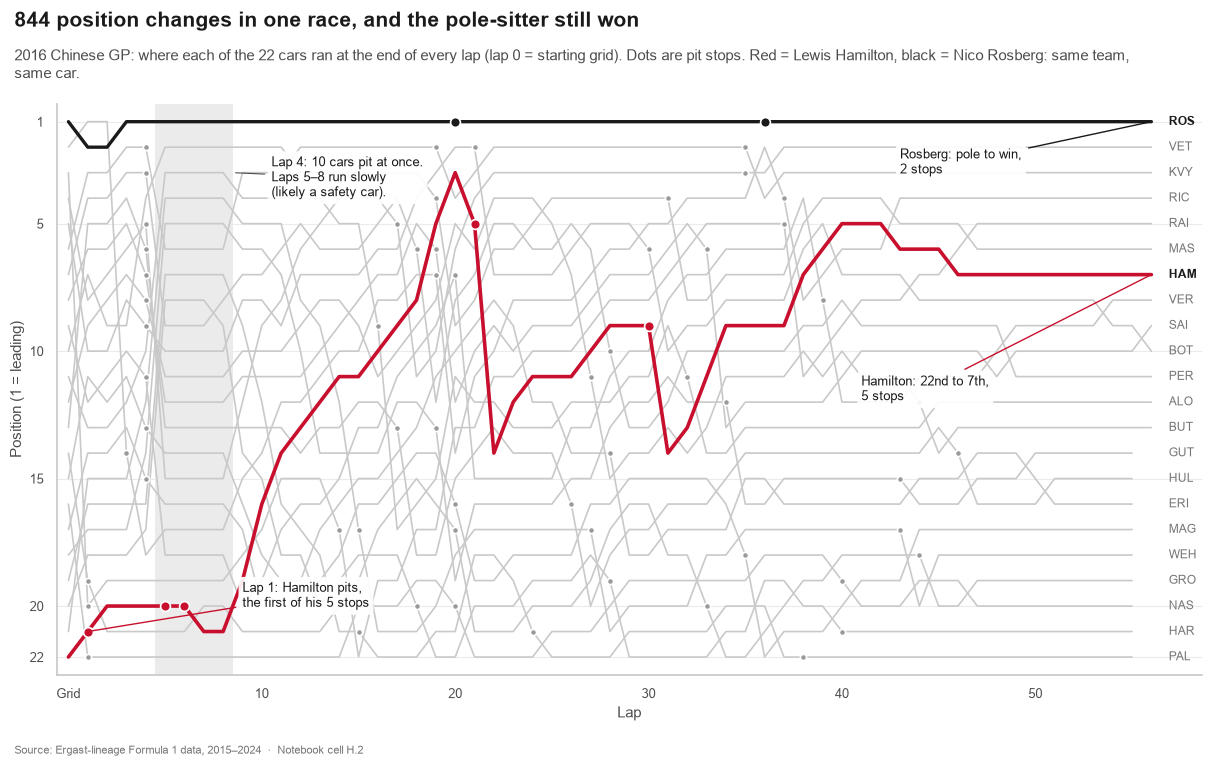

In [15]:
cell("H.2", "Bump chart of the hook race")
hr = results[results["raceId"] == HOOK].set_index("driverId")
ham = hr.index[hr["driverRef"] == "hamilton"][0]
ros = hr.index[hr["driverRef"] == "rosberg"][0]
trace = lap_times[lap_times["raceId"] == HOOK].pivot(index="lap", columns="driverId", values="position")
trace.loc[0] = hr["grid"]                       # lap 0 = starting grid
trace = trace.sort_index()
hook_stops = pit_stops[pit_stops["raceId"] == HOOK]
lap_med = lap_times[lap_times["raceId"] == HOOK].groupby("lap")["lap_ms"].median()
slow = lap_med[lap_med > 1.25 * lap_med.median()].index      # laps run far slower than normal
sc_lap = int(slow.min()) - 1
last = int(trace.index.max())

fact("H.ham_grid", int(hr.loc[ham, "grid"])); fact("H.ham_finish", int(hr.loc[ham, "position"]))
fact("H.ham_stops", int((hook_stops["driverId"] == ham).sum()))
fact("H.ros_stops", int((hook_stops["driverId"] == ros).sum()))
fact("H.ham_first_stop", int(hook_stops.loc[hook_stops["driverId"] == ham, "lap"].min()))
fact("H.slow_first", int(slow.min())); fact("H.slow_last", int(slow.max()))
fact("H.sc_lap", sc_lap); fact("H.n_sc_stops", int((hook_stops["lap"] == sc_lap).sum()))
fact("H.laps", last)

fig, ax = story_fig(f"{T('H.changes')} position changes in one race, and the pole-sitter still won",
                    f"{T('H.race')}: where each of the {T('H.cars')} cars ran at the end of every lap "
                    "(lap 0 = starting grid). Dots are pit stops. Red = Lewis Hamilton, "
                    "black = Nico Rosberg: same team, same car.", width=12, body=6.3)
a = ax["main"]
a.axvspan(slow.min() - 0.5, slow.max() + 0.5, color=GRID, lw=0, zorder=0)
for d in trace.columns:
    if d not in (ham, ros):
        a.plot(trace.index, trace[d], color=LIGHT, lw=1.2, zorder=1, solid_joinstyle="round")
for d, col, lw in [(ros, INK, 2.4), (ham, RED, 2.6)]:
    a.plot(trace.index, trace[d], color=col, lw=lw, zorder=3, solid_joinstyle="round", solid_capstyle="round")
for s in hook_stops.itertuples():
    d, lap = int(s.driverId), int(s.lap)
    col, size, z = (RED, 50, 5) if d == ham else (INK, 50, 5) if d == ros else (DOT, 20, 2)
    a.scatter(lap, trace.loc[lap, d], s=size, color=col, edgecolor="white", linewidth=1.2, zorder=z)
for d, row in hr.iterrows():                    # finishing order on the right
    hl = d in (ham, ros)
    a.text(last + 0.9, row["positionOrder"], row["code"], va="center", fontsize=8.5,
           color=INK if hl else MUTED, fontweight="bold" if hl else "normal")
box = dict(boxstyle="round,pad=0.3", fc="white", ec="none", alpha=0.92)
a.annotate(f"Lap {T('H.sc_lap')}: {T('H.n_sc_stops')} cars pit at once.\n"
           f"Laps {T('H.slow_first')}–{T('H.slow_last')} run slowly\n(likely a safety car).",
           xy=(slow.max() + 0.5, 3), xytext=(slow.max() + 2.5, 3.2), fontsize=9.5, color=INK, va="center",
           bbox=box, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8), zorder=6)
a.annotate(f"Lap {T('H.ham_first_stop')}: Hamilton pits,\nthe first of his {T('H.ham_stops')} stops",
           xy=(1, trace.loc[1, ham]), xytext=(9, 19.6), fontsize=9.5, color=INK, va="center", bbox=box,
           arrowprops=dict(arrowstyle="-", color=RED, lw=1), zorder=6)
a.annotate(f"Rosberg: pole to win,\n{T('H.ros_stops')} stops", xy=(last, 1), xytext=(last - 13, 2.6),
           fontsize=9.5, color=INK, va="center", bbox=box, arrowprops=dict(arrowstyle="-", color=INK, lw=1), zorder=6)
a.annotate(f"Hamilton: {T('H.ham_grid')}nd to {T('H.ham_finish')}th,\n{T('H.ham_stops')} stops",
           xy=(last, hr.loc[ham, "position"]), xytext=(last - 15, 11.5), fontsize=9.5, color=INK, va="center",
           bbox=box, arrowprops=dict(arrowstyle="-", color=RED, lw=1), zorder=6)
a.set_ylim(len(hr) + 0.7, 0.3)
a.set_yticks([1, 5, 10, 15, 20, len(hr)])
a.set_xlim(-0.6, last + 2.6)
a.set_xticks([0] + list(range(10, last + 1, 10)))
a.set_xticklabels(["Grid"] + [str(x) for x in range(10, last + 1, 10)])
a.set_xlabel("Lap"); a.set_ylabel("Position (1 = leading)")
a.grid(axis="x", visible=False)
save(fig, "H2_bump_chart_hook_race")

**What this means.** Under the result (2016 Chinese GP: Rosberg first) sits a chain of events.
Hamilton started 22nd, stopped on lap 1, and made 5 stops in total to climb to 7th.
On lap 4, 10 cars stopped together, just before laps 5–8 ran slowly.
The lines cross most where pit stops cluster: a pit stop *moves* a car through the order.

**Caveat.** One overtake counts as two position changes (one car up, one car down), and pit stops count too.
The dataset has no safety-car field, so the slow laps are *inferred* from lap times.
The data also cannot say *why* Hamilton stopped on lap 1 (race reports say first-lap damage).

**The call you would make.** Do not read a race from the result. Read it from the moves.

---
## Act 1 · Saturday decides more than you think
**The question.** If you know where a driver *starts*, how well can you guess where they *finish*?
And is that the same at every track?

`Cell A1.1` starts with the obvious view: all races pooled together.
We measure the link with the **correlation coefficient r**: 0 means no link, 1 means a perfect straight-line link.
Only classified finishers with a real grid slot are used (pit-lane starts are excluded).

── Cell A1.1 · Grid vs finish, all races pooled ──
   [A1.n] 3,518
   [A1.pooled_r] 0.75
   [A1.r2] 56%
   [A1.pole_win] 53%
   [A1.front_row_win] 77%
   [A1.top3_win] 88%
   [A1.p1_avg_finish] 2.0
   [A1.p10_avg_finish] 9.7
   [A1.p20_avg_finish] 14.2


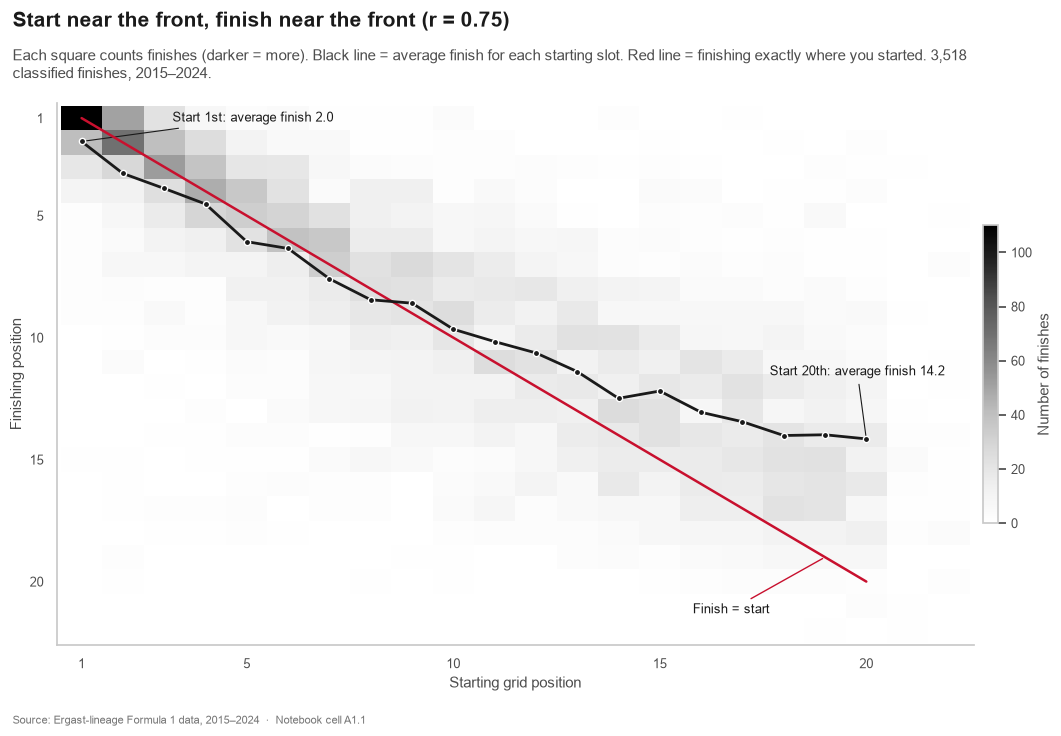

In [16]:
cell("A1.1", "Grid vs finish, all races pooled")
gf = results.dropna(subset=["grid", "position"]).copy()
r_pooled, p_pooled = stats.pearsonr(gf["grid"], gf["position"])
fact("A1.n", len(gf), "{:,}")
fact("A1.pooled_r", r_pooled, "{:.2f}")
fact("A1.r2", r_pooled ** 2 * 100, "{:.0f}%")
wins = results[results["position"] == 1]
fact("A1.pole_win", (wins["grid"] == 1).mean() * 100, "{:.0f}%")
fact("A1.front_row_win", (wins["grid"] <= 2).mean() * 100, "{:.0f}%")
fact("A1.top3_win", (wins["grid"] <= 3).mean() * 100, "{:.0f}%")
mean_by_grid = gf.groupby("grid")["position"].mean()
fact("A1.p1_avg_finish", mean_by_grid.loc[1], "{:.1f}")
fact("A1.p10_avg_finish", mean_by_grid.loc[10], "{:.1f}")
fact("A1.p20_avg_finish", mean_by_grid.loc[20], "{:.1f}")

fig, ax = story_fig(f"Start near the front, finish near the front (r = {T('A1.pooled_r')})",
                    "Each square counts finishes (darker = more). Black line = average finish for each starting slot. "
                    f"Red line = finishing exactly where you started. {T('A1.n')} classified finishes, 2015–2024.",
                    width=10.5, body=6.0)
a = ax["main"]
sns.histplot(data=gf, x="grid", y="position", discrete=(True, True), cmap="Greys", ax=a,
             cbar=True, cbar_kws={"label": "Number of finishes", "shrink": 0.55, "pad": 0.01})
a.plot([1, 20], [1, 20], color=RED, lw=1.8, zorder=4, solid_capstyle="round")
mbg = mean_by_grid.loc[:20]                      # slots 21-22 exist only in 22-car seasons: too few finishes
a.plot(mbg.index, mbg.values, color=INK, lw=2, marker="o", ms=4.5,
       markeredgecolor="white", markeredgewidth=1, zorder=5)
a.annotate("Finish = start", xy=(19, 19), xytext=(15.8, 21.3), fontsize=9.5, color=INK,
           arrowprops=dict(arrowstyle="-", color=RED, lw=1))
a.annotate(f"Start 1st: average finish {T('A1.p1_avg_finish')}", xy=(1, mean_by_grid.loc[1]),
           xytext=(3.2, 1.0), fontsize=9.5, color=INK, va="center",
           arrowprops=dict(arrowstyle="-", color=INK, lw=0.8))
a.annotate(f"Start 20th: average finish {T('A1.p20_avg_finish')}", xy=(20, mean_by_grid.loc[20]),
           xytext=(21.9, 11.4), fontsize=9.5, color=INK, va="center", ha="right",
           arrowprops=dict(arrowstyle="-", color=INK, lw=0.8))
mx = int(max(gf["grid"].max(), gf["position"].max()))
a.set_xlim(0.4, mx + 0.6); a.set_ylim(mx + 0.6, 0.4)
a.set_xticks([1, 5, 10, 15, 20]); a.set_yticks([1, 5, 10, 15, 20])
a.set_xlabel("Starting grid position"); a.set_ylabel("Finishing position")
a.grid(False)
save(fig, "A1_1_grid_vs_finish_pooled")

**What this means.** Across 3,518 finishes, r = 0.75: a strong link.
Pole position won 53% of all races, and 88% of winners started in the top three.
But the black line is flatter than the red one. Front-runners finish slightly *behind* their slot on average
(P1 averages P2.0), and back-markers finish *ahead* of theirs (P20 averages P14.2).
So Sunday can move the order. The next question is *where*.

**Caveat.** Only classified finishers are counted. Cars that retire drop out, which lifts everyone behind them.
That is part of why back-markers seem to "gain".

── Cell A1.2 · Grid-finish correlation circuit by circuit ──


,circuitId,circuit_short,r,n,races,lo,hi
0,6,Monaco,0.878,151.0,9.0,0.835,0.910
1,4,Barcelona,0.826,177.0,10.0,0.773,0.868
2,32,Mexico City,0.815,155.0,9.0,0.754,0.862
3,22,Suzuka,0.812,139.0,8.0,0.746,0.862
4,34,France,0.806,72.0,4.0,0.706,0.874
5,17,Shanghai,0.805,108.0,6.0,0.726,0.863
6,1,Melbourne,0.792,121.0,8.0,0.714,0.850
7,77,Jeddah,0.789,65.0,4.0,0.676,0.866
8,24,Abu Dhabi,0.789,178.0,10.0,0.726,0.839
9,9,Silverstone,0.772,180.0,11.0,0.705,0.825


   [A1.n_circuits] 27
   [A1.median_r] 0.74
   [A1.top_circuit] Monaco
   [A1.top_r] 0.88
   [A1.top_races] 9
   [A1.second_circuit] Barcelona
   [A1.second_r] 0.83
   [A1.third_circuit] Mexico City
   [A1.third_r] 0.81
   [A1.bottom_circuit] Hockenheim
   [A1.bottom_r] 0.52
   [A1.bottom_races] 3
   [A1.bottom_n] 50
   [A1.bottom_lo] 0.29
   [A1.bottom_hi] 0.70
   [A1.second_bottom] Sochi
   [A1.second_bottom_r] 0.66
   [A1.third_bottom] São Paulo
   [A1.third_bottom_r] 0.67


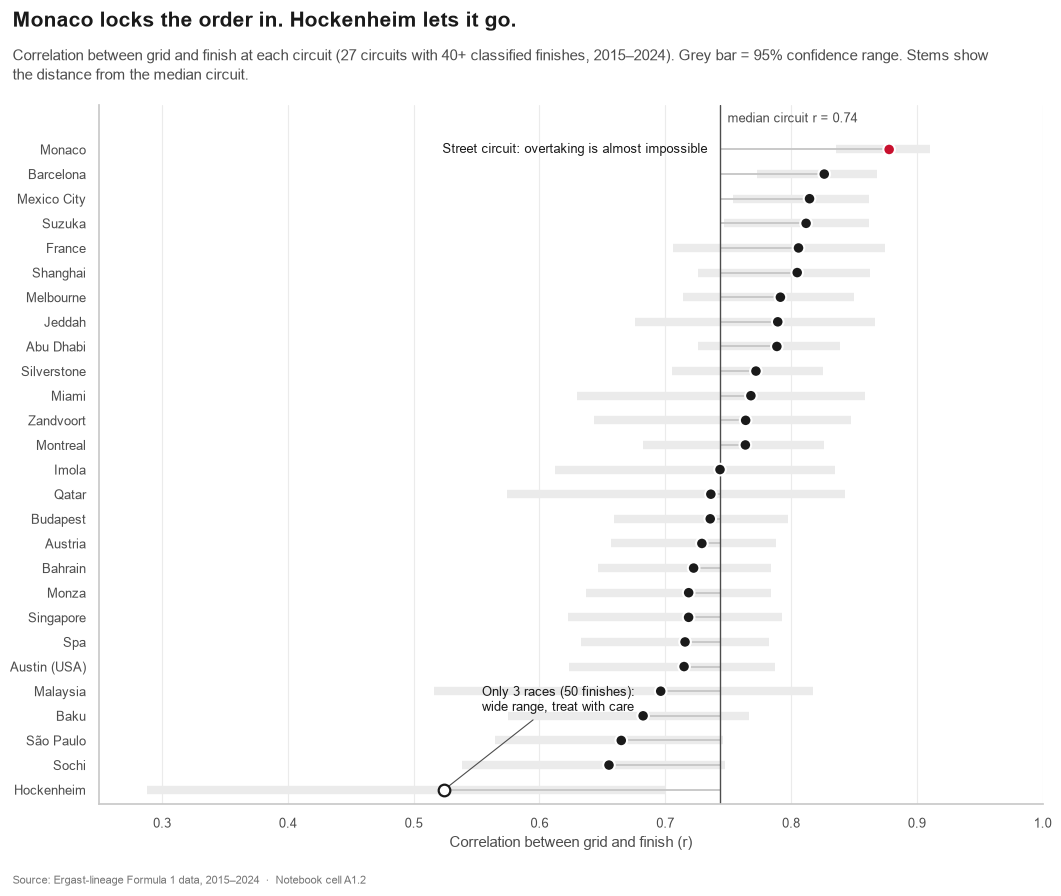

In [17]:
cell("A1.2", "Grid-finish correlation circuit by circuit")
def circuit_r(d):
    r = d["grid"].corr(d["position"])
    n = len(d)
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3)                    # Fisher 95% confidence range
    return pd.Series({"r": r, "n": n, "races": d["raceId"].nunique(),
                      "lo": np.tanh(z - 1.96 * se), "hi": np.tanh(z + 1.96 * se)})
byc = (gf.groupby(["circuitId", "circuit_short"]).apply(circuit_r, include_groups=False)
       .reset_index().query("n >= 40").sort_values("r", ascending=False).reset_index(drop=True))
display(byc.round(3))
top, bot = byc.iloc[0], byc.iloc[-1]
med = byc["r"].median()
fact("A1.n_circuits", len(byc))
fact("A1.median_r", med, "{:.2f}")
fact("A1.top_circuit", top["circuit_short"]); fact("A1.top_r", top["r"], "{:.2f}")
fact("A1.top_races", int(top["races"]))
fact("A1.second_circuit", byc.iloc[1]["circuit_short"]); fact("A1.second_r", byc.iloc[1]["r"], "{:.2f}")
fact("A1.third_circuit", byc.iloc[2]["circuit_short"]); fact("A1.third_r", byc.iloc[2]["r"], "{:.2f}")
fact("A1.bottom_circuit", bot["circuit_short"]); fact("A1.bottom_r", bot["r"], "{:.2f}")
fact("A1.bottom_races", int(bot["races"])); fact("A1.bottom_n", int(bot["n"]))
fact("A1.bottom_lo", bot["lo"], "{:.2f}"); fact("A1.bottom_hi", bot["hi"], "{:.2f}")
fact("A1.second_bottom", byc.iloc[-2]["circuit_short"]); fact("A1.second_bottom_r", byc.iloc[-2]["r"], "{:.2f}")
fact("A1.third_bottom", byc.iloc[-3]["circuit_short"]); fact("A1.third_bottom_r", byc.iloc[-3]["r"], "{:.2f}")

fig, ax = story_fig(f"{T('A1.top_circuit')} locks the order in. {T('A1.bottom_circuit')} lets it go.",
                    f"Correlation between grid and finish at each circuit ({T('A1.n_circuits')} circuits with 40+ classified "
                    "finishes, 2015–2024). Grey bar = 95% confidence range. Stems show the distance from the median circuit.",
                    width=10.5, body=7.6)
a = ax["main"]
y = np.arange(len(byc))
a.hlines(y, byc["lo"], byc["hi"], color=GRID, lw=6, zorder=1)
a.hlines(y, med, byc["r"], color=LIGHT, lw=1.4, zorder=2)
a.axvline(med, color=INK2, lw=1, zorder=2)
colors = [RED if c == top["circuit_short"] else INK for c in byc["circuit_short"]]
sns.scatterplot(x=byc["r"], y=y, hue=byc["circuit_short"], palette=dict(zip(byc["circuit_short"], colors)),
                s=70, edgecolor="white", linewidth=1.5, legend=False, ax=a, zorder=3)
a.scatter(bot["r"], len(byc) - 1, s=70, facecolor="white", edgecolor=INK, linewidth=1.6, zorder=4)
a.set_yticks(y); a.set_yticklabels(byc["circuit_short"]); a.invert_yaxis()
a.text(med + 0.006, -1.1, f"median circuit r = {T('A1.median_r')}", ha="left", fontsize=9, color=INK2)
a.annotate(f"Only {T('A1.bottom_races')} races ({T('A1.bottom_n')} finishes):\nwide range, treat with care",
           xy=(bot["r"], len(byc) - 1), xytext=(bot["r"] + 0.03, len(byc) - 4.2), fontsize=9.5, color=INK,
           arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
a.text(med - 0.01, 0, "Street circuit: overtaking is almost impossible", ha="right", va="center",
       fontsize=9.5, color=INK)
a.set_xlim(0.25, 1.0); a.set_ylim(len(byc) - 0.4, -1.8)
a.set_xlabel("Correlation between grid and finish (r)"); a.set_ylabel("")
a.grid(axis="y", visible=False)
save(fig, "A1_2_circuit_lollipop")

**What this means.** At Monaco (r = 0.88) where you start is almost where you finish:
the street circuit is too narrow to overtake. Barcelona (0.83) and Mexico City (0.81) follow.
At the other end, São Paulo (0.67), Sochi (0.66) and
Hockenheim (0.52) leave room for Sunday to change the order.
The median circuit sits at r = 0.74. Grid position is never unimportant. It is only *more* or *less* important.

**Caveat.** Hockenheim hosted only 3 races in this period (50 finishes),
so its confidence range runs from 0.29 to 0.70. Its exact rank is not reliable.
Correlation shows a link, not a cause: fast cars both qualify well *and* race well.

> **The call you would make.** At Monaco, Barcelona and Mexico City, treat qualifying as the race.
> At Sochi or São Paulo, a poor grid slot can still be fixed on Sunday, so do not risk the car on Saturday.

---
## Act 2 · The stop that costs four places and wins back two
**The question.** A pit stop costs about 23.7 seconds. How many places is that,
and does it matter *when* you stop?

`Cell A2.1` takes every driver's **first** pit stop and reads their position on three laps from the lap-by-lap table:
the lap *before* the stop, 2 laps after, and 10 laps after. Then it splits each race's first stops into thirds:
**early**, **middle** and **late** stoppers *in that race*.

In [18]:
cell("A2.1", "Track position around each first pit stop")
first = pit_stops[pit_stops["stop"] == 1][["raceId", "driverId", "lap"]].rename(columns={"lap": "L"})
pos = lap_times.set_index(["raceId", "driverId", "lap"])["position"]
for col, off in {"p_before": -1, "p_plus2": 2, "p_plus10": 10}.items():
    first[col] = pos.reindex(pd.MultiIndex.from_arrays(
        [first["raceId"], first["driverId"], first["L"] + off])).to_numpy()
und = first.dropna(subset=["p_before", "p_plus2", "p_plus10"]).copy()
und["chg2"] = und["p_before"] - und["p_plus2"]       # negative = places lost
und["chg10"] = und["p_before"] - und["p_plus10"]
und["pct"] = und.groupby("raceId")["L"].rank(method="average", pct=True)
und["timing"] = pd.cut(und["pct"], [0, 1/3, 2/3, 1], labels=["Early", "Middle", "Late"], include_lowest=True)
und = und.merge(results[["raceId", "driverId", "constructorId", "year", "circuitId"]], on=["raceId", "driverId"])
tab = und.groupby("timing", observed=True).agg(n=("chg2", "size"), chg2=("chg2", "mean"), se2=("chg2", "sem"),
                                                chg10=("chg10", "mean"), se10=("chg10", "sem"))
tab["won_back"] = tab["chg10"] - tab["chg2"]
display(tab.round(2))
fact("A2.n", len(und), "{:,}")
for t in ["Early", "Middle", "Late"]:
    k = t.lower()
    fact(f"A2.{k}_n", int(tab.loc[t, "n"]), "{:,}")
    fact(f"A2.{k}_chg2", tab.loc[t, "chg2"], "{:+.1f}")
    fact(f"A2.{k}_chg10", tab.loc[t, "chg10"], "{:+.1f}")
    fact(f"A2.{k}_lost2", -tab.loc[t, "chg2"], "{:.1f}")
    fact(f"A2.{k}_back", tab.loc[t, "won_back"], "{:.1f}")
fact("A2.early_lost2_round", round(-tab.loc["Early", "chg2"]), "{:.0f}")

── Cell A2.1 · Track position around each first pit stop ──


,n,chg2,se2,chg10,se10,won_back
timing,,,,,,
Early,1032,-4.03,0.10,-1.67,0.10,2.35
Middle,1291,-2.98,0.08,-1.64,0.07,1.34
Late,1167,-3.32,0.09,-2.26,0.07,1.07


   [A2.n] 3,490
   [A2.early_n] 1,032
   [A2.early_chg2] -4.0
   [A2.early_chg10] -1.7
   [A2.early_lost2] 4.0
   [A2.early_back] 2.4
   [A2.middle_n] 1,291
   [A2.middle_chg2] -3.0
   [A2.middle_chg10] -1.6
   [A2.middle_lost2] 3.0
   [A2.middle_back] 1.3
   [A2.late_n] 1,167
   [A2.late_chg2] -3.3
   [A2.late_chg10] -2.3
   [A2.late_lost2] 3.3
   [A2.late_back] 1.1
   [A2.early_lost2_round] 4


4

── Cell A2.2 · Undercut chart: before, +2 laps, +10 laps ──


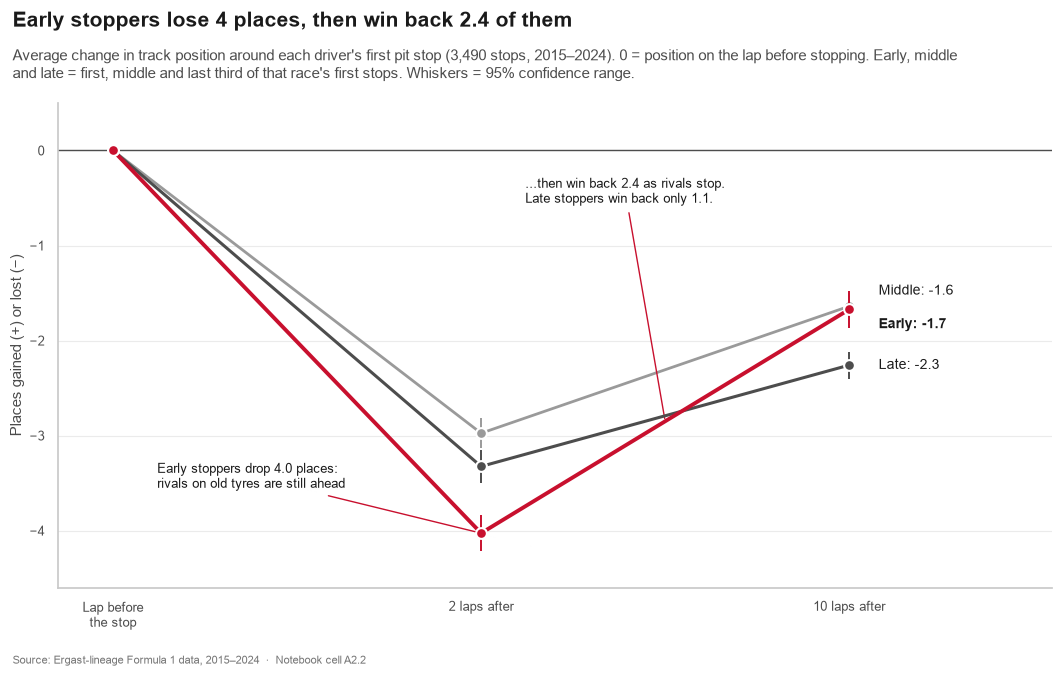

In [19]:
cell("A2.2", "Undercut chart: before, +2 laps, +10 laps")
fig, ax = story_fig(f"Early stoppers lose {T('A2.early_lost2_round')} places, then win back {T('A2.early_back')} of them",
                    "Average change in track position around each driver's first pit stop "
                    f"({T('A2.n')} stops, 2015–2024). 0 = position on the lap before stopping. "
                    "Early, middle and late = first, middle and last third of that race's first stops. "
                    "Whiskers = 95% confidence range.", width=10.5, body=5.4)
a = ax["main"]
xs = [0, 1, 2]
style = {"Early": (RED, 2.8, 5), "Middle": (DOT, 2.0, 3), "Late": (INK2, 2.2, 4)}
for t, (col, lw, z) in style.items():
    ys = [0, tab.loc[t, "chg2"], tab.loc[t, "chg10"]]
    es = [0, 1.96 * tab.loc[t, "se2"], 1.96 * tab.loc[t, "se10"]]
    a.plot(xs, ys, color=col, lw=lw, zorder=z, solid_capstyle="round")
    a.errorbar(xs[1:], ys[1:], yerr=es[1:], fmt="none", ecolor=col, elinewidth=1.4, capsize=0, zorder=z)
    a.scatter(xs, ys, s=60, color=col, edgecolor="white", linewidth=1.5, zorder=z + 1)
    nudge = {"Early": -0.16, "Middle": 0.16, "Late": 0.0}[t]          # Early and Middle end almost together
    a.text(2.08, ys[2] + nudge, f"{t}: {ys[2]:+.1f}", va="center", fontsize=10, color=INK,
           fontweight="bold" if t == "Early" else "normal")
a.annotate(f"Early stoppers drop {T('A2.early_lost2')} places:\nrivals on old tyres are still ahead",
           xy=(1, tab.loc["Early", "chg2"]), xytext=(0.12, -3.55), fontsize=9.5, color=INK,
           arrowprops=dict(arrowstyle="-", color=RED, lw=1))
a.annotate(f"...then win back {T('A2.early_back')} as rivals stop.\nLate stoppers win back only {T('A2.late_back')}.",
           xy=(1.5, (tab.loc["Early", "chg2"] + tab.loc["Early", "chg10"]) / 2), xytext=(1.12, -0.55),
           fontsize=9.5, color=INK, arrowprops=dict(arrowstyle="-", color=RED, lw=1))
a.axhline(0, color=INK2, lw=1, zorder=1)
a.set_xticks(xs); a.set_xticklabels(["Lap before\nthe stop", "2 laps after", "10 laps after"])
a.set_xlim(-0.15, 2.55); a.set_ylim(-4.6, 0.5)
a.set_ylabel("Places gained (+) or lost (−)")
a.grid(axis="x", visible=False)
save(fig, "A2_2_undercut_slope")

**What this means.** Every first stop costs places at once: early stoppers drop 4.0, middle 3.0,
late 3.3. The difference is what happens next. When early stoppers' rivals make *their* stops,
early stoppers win back 2.4 places and end at -1.7. Late stoppers win back only 1.1
and end worst, at -2.3. This is the **undercut** in numbers: the early stop looks bad on the TV screen for
a couple of laps, and that is the strategy working.

**Caveat.** This is *track position*, not time. A driver can fall a place yet close the gap in seconds.
The thirds are relative to each race, so "early" at a one-stop race differs from "early" at a three-stop race.
Some early stops are forced (damage, punctures). `Cell A2.3` checks that these do not drive the result.

In [20]:
cell("A2.3", "Sensitivity: drop first stops in the first 5 laps (often damage)")
und6 = und[und["L"] > 5].copy()
und6["pct"] = und6.groupby("raceId")["L"].rank(method="average", pct=True)
und6["timing"] = pd.cut(und6["pct"], [0, 1/3, 2/3, 1], labels=["Early", "Middle", "Late"], include_lowest=True)
t6 = und6.groupby("timing", observed=True)[["chg2", "chg10"]].mean()
display(t6.round(2))
fact("A2.s_n", len(und6), "{:,}")
fact("A2.s_early_chg2", t6.loc["Early", "chg2"], "{:+.1f}"); fact("A2.s_early_chg10", t6.loc["Early", "chg10"], "{:+.1f}")
fact("A2.s_late_chg2", t6.loc["Late", "chg2"], "{:+.1f}"); fact("A2.s_late_chg10", t6.loc["Late", "chg10"], "{:+.1f}")

── Cell A2.3 · Sensitivity: drop first stops in the first 5 laps (often damage) ──


,chg2,chg10
timing,,
Early,-3.99,-1.67
Middle,-3.22,-1.81
Late,-3.28,-2.23


   [A2.s_n] 3,221
   [A2.s_early_chg2] -4.0
   [A2.s_early_chg10] -1.7
   [A2.s_late_chg2] -3.3
   [A2.s_late_chg10] -2.2


-2.2312556458897923

**Robustness.** Without the stops in the first 5 laps (3,221 stops left), early stoppers still go
-4.0 then -1.7, and late stoppers -3.3 then -2.2. Same pattern.

> **The call you would make.** If your car can survive two or three exposed laps in traffic, stop first.
> The places you lose on the screen are mostly a loan, and the late stopper is the one who never gets them back.

---
## Act 3 · The hidden alarm
This act chains **three tables**: Qualifying, Pit Stops and Race Results.
The link between them is derived: for every race, we find each driver's **teammate** (the other car in the same team).
Teammates drive the same car, so comparing them removes the biggest factor in F1, the car.

**The question.** When one teammate makes more pit stops than the other, what does it tell us?
We start with what most fans see, then test what they assume.

In [21]:
cell("A3.1", "Build teammate pairs: slower vs faster qualifier")
tm = race_level.dropna(subset=["quali_pos"])
tm = tm[tm["raceId"].isin(PIT_RACE_IDS)]                                # stop counts must be known
tm = tm[tm.groupby(["raceId", "constructorId"])["driverId"].transform("size") == 2]
tm = tm.sort_values(["raceId", "constructorId", "quali_pos"]).assign(
    k=lambda d: d.groupby(["raceId", "constructorId"]).cumcount())
fa = tm[tm["k"] == 0].set_index(["raceId", "constructorId"])                # faster qualifier
sl = tm[tm["k"] == 1].set_index(["raceId", "constructorId"])                # slower qualifier
pairs = pd.DataFrame({
    "year": sl["year"], "circuitId": sl["circuitId"],
    "slow_id": sl["driverId"], "fast_id": fa["driverId"],
    "q_gap": sl["quali_pos"] - fa["quali_pos"],                            # places behind teammate on Saturday
    "stop_diff": sl["n_stops"] - fa["n_stops"],                            # StopDiff
    "slow_pos": sl["position"], "fast_pos": fa["position"],
    "slow_first_stop": sl["first_stop_lap"],
    "both_cls": sl["is_classified"] & fa["is_classified"]}).reset_index()
fact("A3.n_pairs", len(pairs), "{:,}")
fact("A3.n_both_cls", int(pairs["both_cls"].sum()), "{:,}")
display(pairs.head())

── Cell A3.1 · Build teammate pairs: slower vs faster qualifier ──
   [A3.n_pairs] 2,085
   [A3.n_both_cls] 1,522


,raceId,constructorId,year,circuitId,slow_id,fast_id,q_gap,stop_diff,slow_pos,fast_pos,slow_first_stop,both_cls
0,926,1,2015,1,825,18,1.0,-1.0,NaN,11.0,NaN,False
1,926,3,2015,1,822,13,3.0,-1.0,NaN,4.0,NaN,False
2,926,5,2015,1,830,832,4.0,0.0,NaN,9.0,32.0,False
3,926,6,2015,1,8,20,1.0,1.0,NaN,3.0,16.0,False
4,926,9,2015,1,826,817,6.0,-1.0,NaN,6.0,NaN,False


### 3a · What everyone sees: more stops, worse finishes

── Cell A3.2 · Number of stops vs finishing position ──
   [A3.zero_stop_n] 2
   [A3.finish_1] 8.5
   [A3.nstops_1] 1,358
   [A3.finish_2] 9.3
   [A3.nstops_2] 1,413
   [A3.finish_3] 10.2
   [A3.nstops_3] 524
   [A3.finish_4] 9.7
   [A3.nstops_4] 261


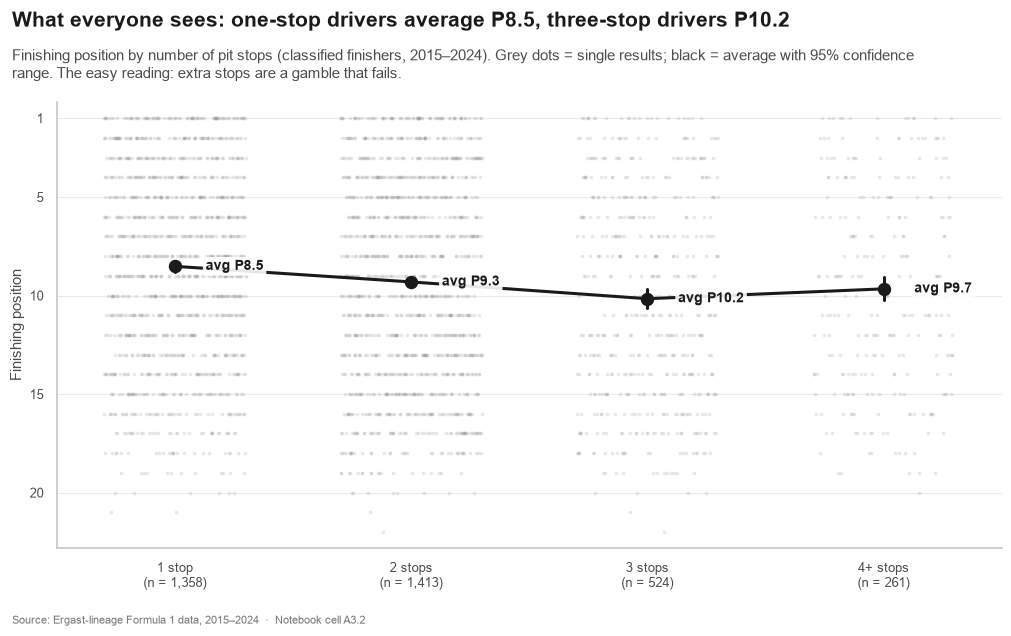

In [22]:
cell("A3.2", "Number of stops vs finishing position")
st = race_level[race_level["raceId"].isin(PIT_RACE_IDS) & race_level["is_classified"]].copy()
fact("A3.zero_stop_n", int((st["n_stops"] == 0).sum()))
st = st[st["n_stops"] >= 1]
st["stops"] = st["n_stops"].clip(upper=4).astype(int).map({1: "1", 2: "2", 3: "3", 4: "4+"})
order = ["1", "2", "3", "4+"]
m = st.groupby("stops")["position"].agg(["mean", "size"]).loc[order]
for s, key in zip(order, ["1", "2", "3", "4"]):
    fact(f"A3.finish_{key}", m.loc[s, "mean"], "{:.1f}")
    fact(f"A3.nstops_{key}", int(m.loc[s, "size"]), "{:,}")

fig, ax = story_fig(f"What everyone sees: one-stop drivers average P{T('A3.finish_1')}, three-stop drivers P{T('A3.finish_3')}",
                    "Finishing position by number of pit stops (classified finishers, 2015–2024). Grey dots = single "
                    "results; black = average with 95% confidence range. The easy reading: extra stops are a gamble that fails.",
                    width=10, body=5.0)
a = ax["main"]
sns.stripplot(data=st, x="stops", y="position", order=order, color=DOT, alpha=0.22, jitter=0.3, size=2.6, ax=a, zorder=1)
sns.pointplot(data=st, x="stops", y="position", order=order, color=INK, errorbar=("ci", 95), seed=0,
              markersize=8, linewidth=2.2, ax=a, zorder=3)
for i, s in enumerate(order):
    a.text(i + 0.13, m.loc[s, "mean"], f"avg P{m.loc[s, 'mean']:.1f}", va="center", fontsize=10, color=INK,
           fontweight="bold", bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.9))
a.set_xticks(range(4)); a.set_xticklabels([f"{s} stop{'s' if s != '1' else ''}\n(n = {m.loc[s, 'size']:,})" for s in order])
a.set_ylim(st["position"].max() + 0.8, 0.2); a.set_yticks([1, 5, 10, 15, 20])
a.set_xlabel(""); a.set_ylabel("Finishing position")
a.grid(axis="x", visible=False)
save(fig, "A3_2_stops_vs_finish")

One-stop drivers average P8.5; two-stop P9.3; three-stop P10.2.
Four or more stops is slightly *better* (P9.7), probably because those are chaotic races (rain, red flags)
where everyone stops a lot.
(Zero-stop finishes are rare, 2 cases, mostly rain or red-flag races, so they are left out.)
The usual story: *a driver who is far behind gambles on an extra stop, and the gamble fails.*
If that were true, the driver who qualified further behind the teammate should stop more often. `Cell A3.3` tests it.

### 3b · Test the assumption: does falling behind make teams gamble?
**StopDiff** = stops made by the slower qualifier − stops made by the faster teammate.
A positive StopDiff means the slower qualifier made the extra stop.

── Cell A3.3 · Qualifying gap vs StopDiff ──
   [A3.r_gap] +0.02
   [A3.r_gap_p] 0.34
   [A3.share_extra] 24%


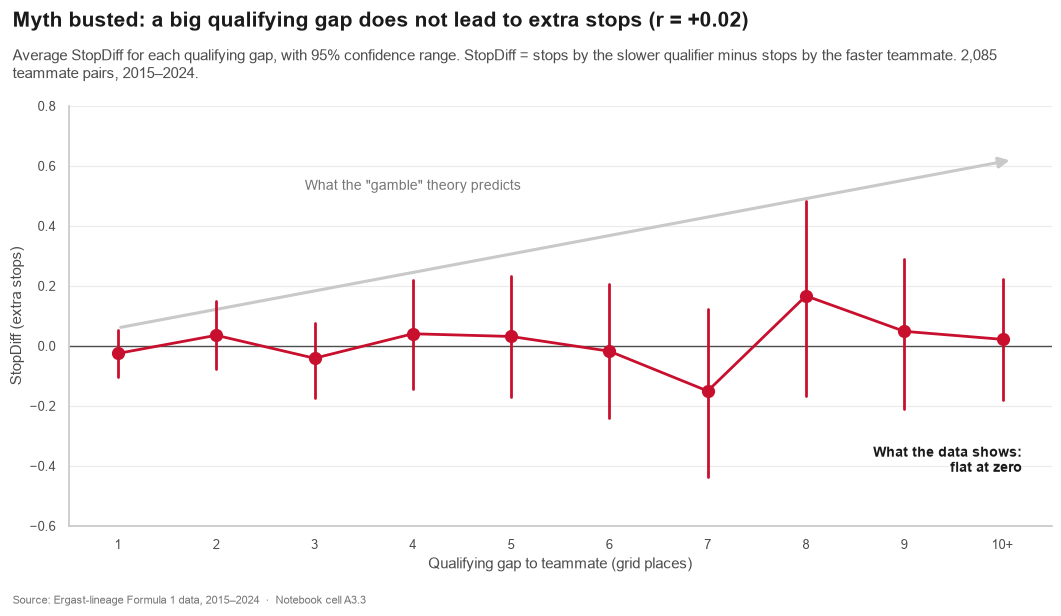

In [23]:
cell("A3.3", "Qualifying gap vs StopDiff")
r_gap, p_gap = stats.pearsonr(pairs["q_gap"], pairs["stop_diff"])
fact("A3.r_gap", r_gap, "{:+.2f}")
fact("A3.r_gap_p", p_gap, "{:.2f}")
fact("A3.share_extra", (pairs["stop_diff"] > 0).mean() * 100, "{:.0f}%")
pairs["gap_bin"] = pairs["q_gap"].clip(upper=10).astype(int).astype(str).replace({"10": "10+"})
gorder = [str(i) for i in range(1, 10)] + ["10+"]

fig, ax = story_fig(f"Myth busted: a big qualifying gap does not lead to extra stops (r = {T('A3.r_gap')})",
                    "Average StopDiff for each qualifying gap, with 95% confidence range. StopDiff = stops by the slower "
                    f"qualifier minus stops by the faster teammate. {T('A3.n_pairs')} teammate pairs, 2015–2024.",
                    width=10.5, body=4.8)
a = ax["main"]
a.axhline(0, color=INK2, lw=1, zorder=1)
a.annotate("", xy=(9.1, 0.62), xytext=(0, 0.06),
           arrowprops=dict(arrowstyle="-|>", color=LIGHT, lw=2.2, mutation_scale=16), zorder=1)
a.text(3.0, 0.52, "What the \"gamble\" theory predicts", fontsize=10, color=MUTED, ha="center")
sns.pointplot(data=pairs, x="gap_bin", y="stop_diff", order=gorder, color=RED, errorbar=("ci", 95), seed=0,
              markersize=8, linewidth=2, ax=a, zorder=3)
a.text(9.2, -0.42, "What the data shows:\nflat at zero", ha="right", fontsize=10, color=INK, fontweight="bold")
a.set_xlabel("Qualifying gap to teammate (grid places)"); a.set_ylabel("StopDiff (extra stops)")
a.set_ylim(-0.6, 0.8)
a.grid(axis="x", visible=False)
save(fig, "A3_3_gap_vs_stopdiff")

**The assumption is dead.** The correlation between qualifying gap and StopDiff is r = +0.02 (p = 0.34): no link at all.
Drivers who qualified ten places behind their teammate do not stop more often than drivers who were one place behind.
So if extra stops are not a planned gamble, what are they?

### 3c · The reveal: the extra stop is an alarm
We now look only at pairs where **both** cars were classified (1,522 pairs),
and ask: how often does the slower qualifier finish *ahead* of the teammate?

── Cell A3.4 · Beat-your-teammate rate, with vs without an extra stop ──


,rate_extra,n_extra,rate_no,n_no,z,p
All pairs,12.238,286.0,34.223,1236.0,-7.305,0.000
Small gap\n1–3 places,12.791,172.0,41.312,823.0,-7.071,0.000
Medium gap\n4–7 places,11.765,68.0,23.420,269.0,-2.106,0.035
Large gap\n8+ places,10.870,46.0,13.889,144.0,-0.527,0.598


   [A3.rate_extra] 12%
   [A3.rate_extra_1] 12.2%
   [A3.rate_no] 34%
   [A3.rate_no_1] 34.2%
   [A3.n_extra] 286
   [A3.n_no] 1,236
   [A3.z] -7.3
   [A3.med_gap_extra] +3
   [A3.med_gap_no] +1
   [A3.small_extra] 13%
   [A3.small_no] 41%
   [A3.small_n_extra] 172
   [A3.small_p] 1.5e-12
   [A3.medium_extra] 12%
   [A3.medium_no] 23%
   [A3.medium_n_extra] 68
   [A3.medium_p] 0.035
   [A3.large_extra] 11%
   [A3.large_no] 14%
   [A3.large_n_extra] 46
   [A3.large_p] 0.6


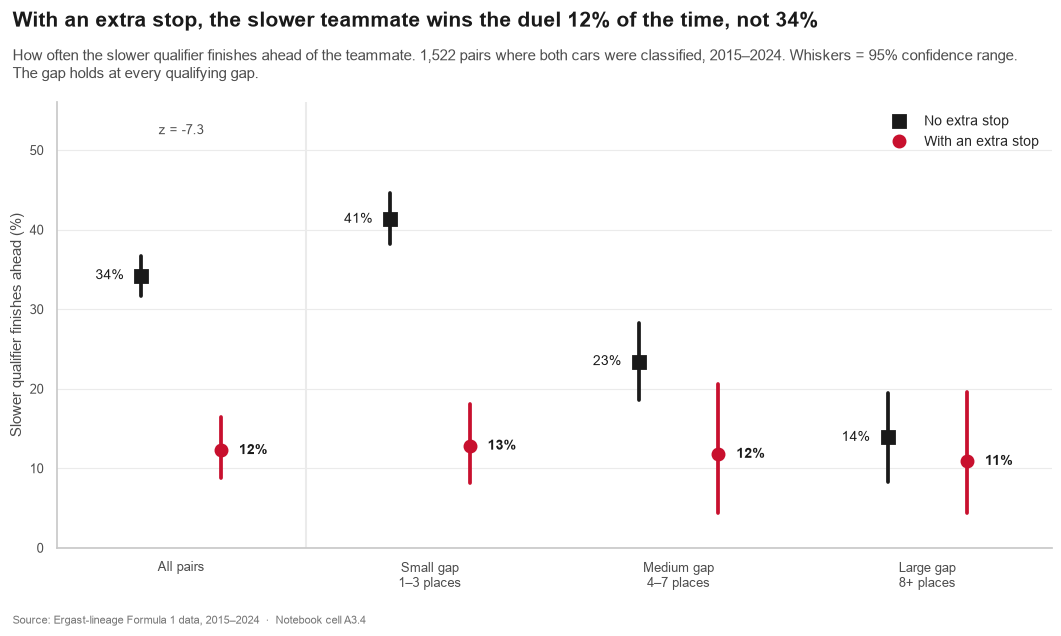

In [24]:
cell("A3.4", "Beat-your-teammate rate, with vs without an extra stop")
bc = pairs[pairs["both_cls"]].copy()
bc["extra"] = bc["stop_diff"] > 0
bc["beat"] = (bc["slow_pos"] < bc["fast_pos"]).astype(float) * 100
bc["gap"] = bc["slow_pos"] - bc["fast_pos"]                 # + = slower qualifier finished behind
bc["group"] = np.where(bc["extra"], "With an extra stop", "No extra stop")
bc["bucket"] = pd.cut(bc["q_gap"], [0, 3, 7, 99], labels=["Small gap\n1–3 places", "Medium gap\n4–7 places",
                                                          "Large gap\n8+ places"]).astype(str)

def two_prop(d):
    x1, n1 = d.loc[d["extra"], "beat"].sum() / 100, d["extra"].sum()
    x2, n2 = d.loc[~d["extra"], "beat"].sum() / 100, (~d["extra"]).sum()
    p = (x1 + x2) / (n1 + n2)
    z = (x1 / n1 - x2 / n2) / np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    return pd.Series({"rate_extra": 100 * x1 / n1, "n_extra": n1, "rate_no": 100 * x2 / n2, "n_no": n2,
                      "z": z, "p": 2 * stats.norm.sf(abs(z))})

overall = two_prop(bc)
BUCKETS = ["Small gap\n1–3 places", "Medium gap\n4–7 places", "Large gap\n8+ places"]
by_b = bc.groupby("bucket").apply(two_prop, include_groups=False).loc[BUCKETS]
display(pd.concat([overall.rename("All pairs").to_frame().T, by_b]).round(3))
fact("A3.rate_extra", overall["rate_extra"], "{:.0f}%"); fact("A3.rate_extra_1", overall["rate_extra"], "{:.1f}%")
fact("A3.rate_no", overall["rate_no"], "{:.0f}%"); fact("A3.rate_no_1", overall["rate_no"], "{:.1f}%")
fact("A3.n_extra", int(overall["n_extra"]), "{:,}"); fact("A3.n_no", int(overall["n_no"]), "{:,}")
fact("A3.z", overall["z"], "{:.1f}")
fact("A3.med_gap_extra", bc.loc[bc["extra"], "gap"].median(), "{:+.0f}")
fact("A3.med_gap_no", bc.loc[~bc["extra"], "gap"].median(), "{:+.0f}")
for b, key in zip(by_b.index, ["small", "medium", "large"]):
    fact(f"A3.{key}_extra", by_b.loc[b, "rate_extra"], "{:.0f}%"); fact(f"A3.{key}_no", by_b.loc[b, "rate_no"], "{:.0f}%")
    fact(f"A3.{key}_n_extra", int(by_b.loc[b, "n_extra"])); fact(f"A3.{key}_p", by_b.loc[b, "p"], "{:.2g}")

plot = pd.concat([bc.assign(bucket="All pairs"), bc])
xorder = ["All pairs"] + list(by_b.index)
fig, ax = story_fig(f"With an extra stop, the slower teammate wins the duel {T('A3.rate_extra')} of the time, not {T('A3.rate_no')}",
                    f"How often the slower qualifier finishes ahead of the teammate. {T('A3.n_both_cls')} pairs where both cars "
                    "were classified, 2015–2024. Whiskers = 95% confidence range. The gap holds at every qualifying gap.",
                    width=10.5, body=5.0)
a = ax["main"]
sns.pointplot(data=plot, x="bucket", y="beat", hue="group", order=xorder,
              hue_order=["No extra stop", "With an extra stop"], palette=[INK, RED], markers=["s", "o"],
              linestyle="none", dodge=0.32, errorbar=("ci", 95), seed=0, markersize=8, ax=a)
for i, b in enumerate(xorder):
    row = overall if b == "All pairs" else by_b.loc[b]
    a.text(i - 0.2, row["rate_no"], f"{row['rate_no']:.0f}%  ", ha="right", va="center", fontsize=10, color=INK)
    a.text(i + 0.2, row["rate_extra"], f"  {row['rate_extra']:.0f}%", ha="left", va="center", fontsize=10,
           color=INK, fontweight="bold")
a.axvline(0.5, color=GRID, lw=1.5)
a.text(0.0, 52, f"z = {T('A3.z')}", ha="center", fontsize=9.5, color=INK2)
a.set_ylim(0, 56); a.set_xlabel(""); a.set_ylabel("Slower qualifier finishes ahead (%)")
a.legend(title="", loc="upper right", fontsize=10)
a.grid(axis="x", visible=False)
save(fig, "A3_4_teammate_duel")

**The reveal.** With an extra stop, the slower qualifier finished ahead of the teammate only **12.2%** of the time
(n = 286). Without one, **34.2%** (n = 1,236). A two-proportion test gives z = -7.3,
far beyond what chance produces. It holds whether the qualifying gap was small (13% vs 41%),
medium (12% vs 23%) or large (11% vs 14%).

**Caveat on the large-gap bucket.** There the difference is small and only 46 pairs made an extra stop
(p = 0.6). The direction holds; the strength does not. A driver who qualified 8+ places behind rarely beats
the teammate anyway.

── Cell A3.5 · The distress signal: who made the extra stop, and when ──
   [A3.beat_when_mate_extra] 64%
   [A3.n_mate_extra] 240
   [A3.beat_when_equal] 27%
   [A3.n_equal] 996
   [A3.early_stop_extra] 27%
   [A3.early_stop_no] 9%


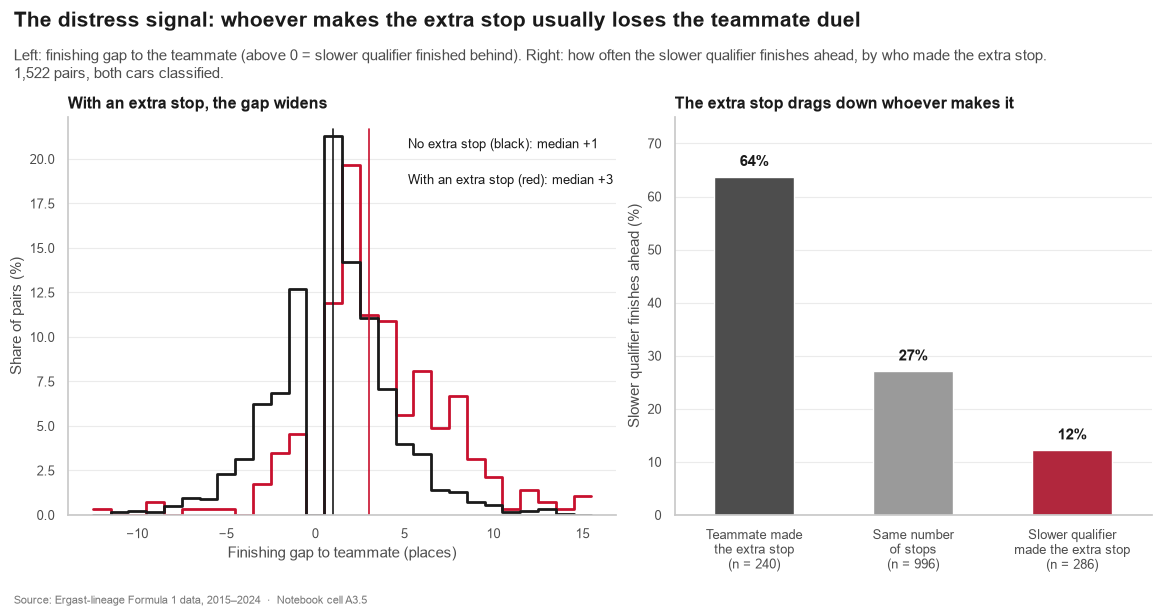

In [25]:
cell("A3.5", "The distress signal: who made the extra stop, and when")
bc["who"] = np.select([bc["stop_diff"] > 0, bc["stop_diff"] < 0], ["Slower qualifier\nmade the extra stop",
                       "Teammate made\nthe extra stop"], default="Same number\nof stops")
worder = ["Teammate made\nthe extra stop", "Same number\nof stops", "Slower qualifier\nmade the extra stop"]
w = bc.groupby("who")["beat"].agg(["mean", "size"]).loc[worder]
fact("A3.beat_when_mate_extra", w.iloc[0]["mean"], "{:.0f}%"); fact("A3.n_mate_extra", int(w.iloc[0]["size"]))
fact("A3.beat_when_equal", w.iloc[1]["mean"], "{:.0f}%"); fact("A3.n_equal", int(w.iloc[1]["size"]))
early = bc.groupby("extra")["slow_first_stop"].apply(lambda s: (s <= 3).mean() * 100)
fact("A3.early_stop_extra", early[True], "{:.0f}%"); fact("A3.early_stop_no", early[False], "{:.0f}%")

fig, ax = story_fig("The distress signal: whoever makes the extra stop usually loses the teammate duel",
                    "Left: finishing gap to the teammate (above 0 = slower qualifier finished behind). Right: how often the "
                    f"slower qualifier finishes ahead, by who made the extra stop. {T('A3.n_both_cls')} pairs, both cars classified.",
                    width=11.5, body=4.8, mosaic=[["gap", "who"]], width_ratios=[1.15, 1])
a = ax["gap"]
sns.histplot(data=bc[bc["gap"].between(-12, 15)], x="gap", hue="group", hue_order=["No extra stop", "With an extra stop"],
             palette=[INK, RED], element="step", fill=False, stat="percent", common_norm=False, discrete=True,
             linewidth=2, ax=a, legend=False)
for grp, col, med_key, yy, word in [("No extra stop", INK, "A3.med_gap_no", 0.93, "black"),
                                     ("With an extra stop", RED, "A3.med_gap_extra", 0.84, "red")]:
    mv = bc.loc[bc["group"] == grp, "gap"].median()
    a.axvline(mv, color=col, lw=1.2, ymax=0.97)
    a.text(5.2, yy, f"{grp} ({word}): median {T(med_key)}", fontsize=9.5, color=INK, va="center",
           transform=a.get_xaxis_transform())
a.set_xlabel("Finishing gap to teammate (places)"); a.set_ylabel("Share of pairs (%)")
a.set_title("With an extra stop, the gap widens", loc="left")
a.grid(axis="x", visible=False)
b = ax["who"]
sns.barplot(x=w.index, y=w["mean"], hue=w.index, palette=[INK2, DOT, RED], legend=False, width=0.5, ax=b)
for i, v in enumerate(w["mean"]):
    b.text(i, v + 2, f"{v:.0f}%", ha="center", fontsize=11, color=INK, fontweight="bold")
b.set_xticks(range(3)); b.set_xticklabels([f"{k}\n(n = {n:,})" for k, n in zip(w.index, w["size"])], fontsize=9)
b.set_ylim(0, 75); b.set_xlabel(""); b.set_ylabel("Slower qualifier finishes ahead (%)")
b.set_title("The extra stop drags down whoever makes it", loc="left")
b.grid(axis="x", visible=False)
save(fig, "A3_5_distress_signal")

**What this means.** The extra stop is not about *who qualified slower*. It drags down whoever makes it.
When the *teammate* made the extra stop, the slower qualifier finished ahead 64% of the time;
with equal stops, 27%; when the slower qualifier made it, 12%. The median finishing gap
widens from +1 to +3 places.
There is also a clue about *why*: 27% of extra-stop drivers made their first stop in laps 1–3,
against 9% of the others. Stopping that early is rarely a plan. It usually means damage or a puncture.

**Honest framing.** The extra stop is a **symptom** of trouble (damage, a puncture, a spin, bad safety-car timing).
It is **not a weapon**, and it is **not the cause** of the lost result. Telling a driver "make fewer stops" would not
fix anything; the trouble came first. This is a correlation, measured on observational data, and we treat it as a
*warning light*, not as a lever.

> **The call you would make.** When your second car suddenly needs a stop the plan did not have, treat it as an alarm:
> something has gone wrong. Do not expect that stop to win places back. Protect the other car's result.

---
## Act 4 · The car sets the ceiling
Acts 1–3 were about decisions made on a race weekend. This act zooms out to ten seasons.
**The question.** How much of a result is decided by which team you drive for?

In [26]:
cell("A4.1", "Constructor points share, the four top teams (Plotly)")
share = constructor_final.pivot_table(index="year", columns="constructorId", values="points_share") * 100
pts = constructor_final.pivot_table(index="year", columns="constructorId", values="points")
champ = constructor_final[constructor_final["position"] == 1].set_index("year")["constructorId"]
TEAMS = {131: "Mercedes", 9: "Red Bull", 1: "McLaren", 6: "Ferrari"}
yrs = share.index.tolist()
fact("A4.mer_2015", share.loc[2015, 131], "{:.1f}%"); fact("A4.mer_2023", share.loc[2023, 131], "{:.1f}%")
fact("A4.rbr_2015", share.loc[2015, 9], "{:.1f}%"); fact("A4.rbr_2023", share.loc[2023, 9], "{:.1f}%")
fact("A4.mcl_2015", share.loc[2015, 1], "{:.1f}%"); fact("A4.mcl_2024", share.loc[2024, 1], "{:.1f}%")
fact("A4.fer_2024", share.loc[2024, 6], "{:.1f}%"); fact("A4.rbr_2024", share.loc[2024, 9], "{:.1f}%")
fact("A4.mer_2016", share.loc[2016, 131], "{:.1f}%")
fact("A4.mer_titles", int((champ == 131).sum())); fact("A4.rbr_titles", int((champ == 9).sum()))
fact("A4.mer_last_title", int(champ[champ == 131].index.max()))
fact("A4.fer_best", share[6].max(), "{:.1f}%"); fact("A4.fer_best_year", int(share[6].idxmax()))
fact("A4.fer_worst", share[6].min(), "{:.1f}%"); fact("A4.fer_worst_year", int(share[6].idxmin()))
swing = (share[list(TEAMS)] - share[list(TEAMS)].shift(3)).stack().rename("pp").reset_index()
big = swing.loc[swing["pp"].abs().idxmax()]
fact("A4.swing_team", TEAMS[int(big["constructorId"])]); fact("A4.swing_pp", abs(big["pp"]), "{:.0f}")
fact("A4.swing_dir", "rose" if big["pp"] > 0 else "fell")
fact("A4.swing_from", int(big["year"]) - 3); fact("A4.swing_to", int(big["year"]))

fig = make_subplots(rows=1, cols=4, shared_yaxes=True, horizontal_spacing=0.045,
                    subplot_titles=["<b>Mercedes</b>", "<b>Red Bull</b>", "<b>McLaren</b>", "<b>Ferrari</b>"])
for i, (cid, name) in enumerate([(131, "Mercedes"), (9, "Red Bull"), (1, "McLaren"), (6, "Ferrari")], start=1):
    fig.add_trace(go.Scatter(x=yrs, y=share[cid], mode="lines", line=dict(color=INK, width=2.5),
                             fill="tozeroy", fillcolor="rgba(26,26,26,0.07)",
                             customdata=np.c_[pts[cid]], name=name,
                             hovertemplate=f"<b>{name}</b> %{{x}}<br>%{{y:.1f}}% of all points<br>%{{customdata[0]:.0f}} points<extra></extra>"),
                  row=1, col=i)
    cy = [y for y in yrs if champ.loc[y] == cid]
    if cy:
        fig.add_trace(go.Scatter(x=cy, y=share.loc[cy, cid], mode="markers", hoverinfo="skip",
                                 marker=dict(color=RED, size=11, line=dict(color="white", width=2))), row=1, col=i)
    # (year, x-anchor, x-shift, y-shift) for each direct label, placed off the line
    for y, xa, xs, ys in {131: [(2015, "left", 4, 14), (2023, "center", 0, -16)],
                          9: [(2015, "left", 8, 0), (2023, "center", 0, 15)],
                          1: [(2015, "left", -4, 22), (2024, "right", -6, 12)],
                          6: [(2018, "center", 0, 15), (2020, "center", 0, -15)]}[cid]:
        fig.add_annotation(x=y, y=share.loc[y, cid], text=f"{share.loc[y, cid]:.1f}%", showarrow=False,
                           xanchor=xa, xshift=xs, yshift=ys, font=dict(size=12, color=INK), row=1, col=i)
fig.update_yaxes(range=[0, 42], ticksuffix="%", gridcolor=GRID, showgrid=True, zeroline=False)
fig.update_yaxes(title_text="Share of all constructor points", row=1, col=1)
fig.update_xaxes(tickvals=[2015, 2018, 2021, 2024], showgrid=False, range=[2014.5, 2024.6])
plotly_story(fig, "Three eras in ten seasons: Mercedes, then Red Bull, then McLaren",
             "Each team's share of all constructor championship points. Red dot = constructors' champion that season. "
             "Hover for points.",
             height=470)
save_plotly(fig, "A4_1_points_share_eras")

── Cell A4.1 · Constructor points share, the four top teams (Plotly) ──
   [A4.mer_2015] 36.6%
   [A4.mer_2023] 16.6%
   [A4.rbr_2015] 9.7%
   [A4.rbr_2023] 35.0%
   [A4.mcl_2015] 1.4%
   [A4.mcl_2024] 25.0%
   [A4.fer_2024] 24.5%
   [A4.rbr_2024] 22.2%
   [A4.mer_2016] 36.1%
   [A4.mer_titles] 7
   [A4.rbr_titles] 2
   [A4.mer_last_title] 2021
   [A4.fer_best] 27.7%
   [A4.fer_best_year] 2018
   [A4.fer_worst] 7.6%
   [A4.fer_worst_year] 2020
   [A4.swing_team] Ferrari
   [A4.swing_pp] 18
   [A4.swing_dir] fell
   [A4.swing_from] 2017
   [A4.swing_to] 2020
PNG export skipped: RuntimeError 
Image export requires the Kaleido package, v1.0.0 or greater,
which can be installed using pip:

    $ pip install --upgrade "kaleido>=1"



**What this means.** Mercedes took 36.6% of all points in 2015 and won 7 constructors' titles in a row
(to 2021), then fell to 16.6% by 2023. Red Bull rose from 9.7% to 35.0%.
McLaren climbed from 1.4% to 25.0% and won 2024, just ahead of Ferrari (24.5%).
Ferrari peaked at 27.7% in 2018, fell to 7.6% in 2020, and never won a title in this period.
The biggest three-season swing: Ferrari's share fell by 18 percentage points between
2017 and 2020. Changes that size are an engineering story, not a race-day decision.

**Why Plotly here.** Four small panels with one shared axis make the eras easy to compare;
hovering gives the exact share and points for any team-season without cluttering the chart.

── Cell A4.2 · Genuine DNF rate by season ──
   [A4.dnf_2015] 21.4%
   [A4.dnf_2024] 11.3%
   [A4.dnf_2017] 23.8%
   [A4.dnf_2022] 16.8%
   [A4.dnf_2015_r] 21%
   [A4.dnf_2024_r] 11%
   [A4.dnf_best_team] Mercedes
   [A4.dnf_best] 7.4%
   [A4.dnf_worst_team] Toro Rosso
   [A4.dnf_worst] 25.5%


,constructorId,mean,size
constructor,,,
Mercedes,131,7.4,418
Alfa Romeo,51,13.5,208
Aston Martin,117,14.4,180
Ferrari,6,14.6,418
Force India,10,14.8,162
Red Bull,9,15.3,418
Manor Marussia,209,15.4,78
Alpine F1 Team,214,16.1,180
AlphaTauri,213,16.3,166


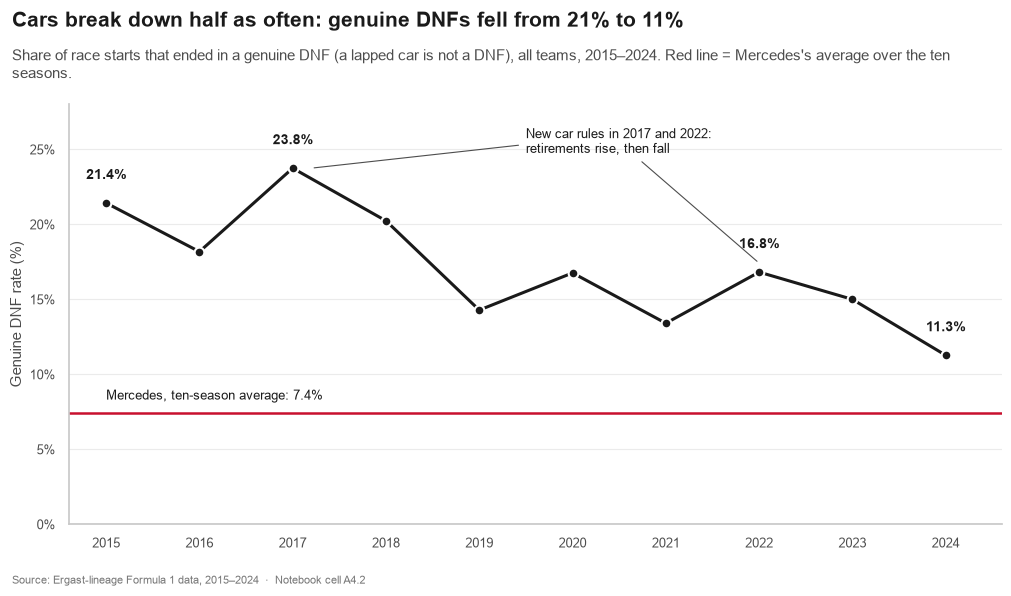

In [27]:
cell("A4.2", "Genuine DNF rate by season")
dnf_y = results.groupby("year")["is_dnf"].mean() * 100
dnf_team = (results.groupby(["constructorId", "constructor"])["is_dnf"].agg(["mean", "size"])
            .query("size >= 60").sort_values("mean").reset_index("constructorId"))
fact("A4.dnf_2015", dnf_y.loc[2015], "{:.1f}%"); fact("A4.dnf_2024", dnf_y.loc[2024], "{:.1f}%")
fact("A4.dnf_2017", dnf_y.loc[2017], "{:.1f}%"); fact("A4.dnf_2022", dnf_y.loc[2022], "{:.1f}%")
fact("A4.dnf_2015_r", dnf_y.loc[2015], "{:.0f}%"); fact("A4.dnf_2024_r", dnf_y.loc[2024], "{:.0f}%")
fact("A4.dnf_best_team", dnf_team.index[0]); fact("A4.dnf_best", dnf_team["mean"].iloc[0] * 100, "{:.1f}%")
fact("A4.dnf_worst_team", dnf_team.index[-1]); fact("A4.dnf_worst", dnf_team["mean"].iloc[-1] * 100, "{:.1f}%")
display(dnf_team.assign(mean=lambda d: d["mean"] * 100).round(1))

fig, ax = story_fig(f"Cars break down half as often: genuine DNFs fell from {T('A4.dnf_2015_r')} to {T('A4.dnf_2024_r')}",
                    "Share of race starts that ended in a genuine DNF (a lapped car is not a DNF), all teams, 2015–2024. "
                    f"Red line = {T('A4.dnf_best_team')}'s average over the ten seasons.", width=10, body=4.6)
a = ax["main"]
a.plot(dnf_y.index, dnf_y.values, color=INK, lw=2.2, marker="o", ms=7, markeredgecolor="white", markeredgewidth=1.5, zorder=3)
a.axhline(dnf_team["mean"].iloc[0] * 100, color=RED, lw=1.8, zorder=2)
a.text(2015, dnf_team["mean"].iloc[0] * 100 + 0.7, f"{T('A4.dnf_best_team')}, ten-season average: {T('A4.dnf_best')}",
       va="bottom", fontsize=9.5, color=INK)
for yv, ha, dy in [(2015, "center", 1.6), (2024, "center", 1.6), (2017, "center", 1.6), (2022, "center", 1.6)]:
    a.text(yv, dnf_y.loc[yv] + dy, f"{dnf_y.loc[yv]:.1f}%", ha=ha, fontsize=10, color=INK, fontweight="bold")
a.annotate("New car rules in 2017 and 2022:\nretirements rise, then fall", xy=(2022, dnf_y.loc[2022] + 0.6),
           xytext=(2019.5, 25.5), fontsize=9.5, color=INK, va="center", arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
a.annotate("", xy=(2017.2, dnf_y.loc[2017]), xytext=(2019.45, 25.3), arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
a.set_ylim(0, 28); a.set_xlim(2014.6, 2024.6)
a.set_xticks(range(2015, 2025)); a.set_ylabel("Genuine DNF rate (%)")
a.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(decimals=0))
a.grid(axis="x", visible=False)
save(fig, "A4_2_dnf_rate")

**What this means.** In 2015, 21.4% of starts ended in a genuine retirement; in 2024, 11.3%.
The fall is not smooth: 2017 (23.8%) and 2022 (16.8%) were both years of new technical rules.
Mercedes retired only 7.4% of the time over ten seasons, the best of any team with 60+ starts
(Toro Rosso was worst at 25.5%). A car that finishes can score; reliability is part of the ceiling.

**Caveat.** "Genuine DNF" mixes mechanical failures with crashes. The link to rule changes is a plausible
explanation, not something this data can prove.

── Cell A4.3 · Race wins by driver, and how many came in the champion team's car ──
   [A4.wins_champ_car] 67%


,wins,champ_wins,podiums
driver,,,
Lewis Hamilton,72,70,132
Max Verstappen,63,34,112
Nico Rosberg,15,15,31
Sebastian Vettel,14,0,56
Valtteri Bottas,10,10,61
Charles Leclerc,8,0,43
Sergio Pérez,6,4,35
Daniel Ricciardo,5,0,24
Carlos Sainz,4,0,27


   [A4.n_winners] 15
   [A4.top2_wins] 65%
   [A4.ham_wins] 72
   [A4.ham_champ_wins] 70
   [A4.ver_wins] 63
   [A4.ver_champ_wins] 34


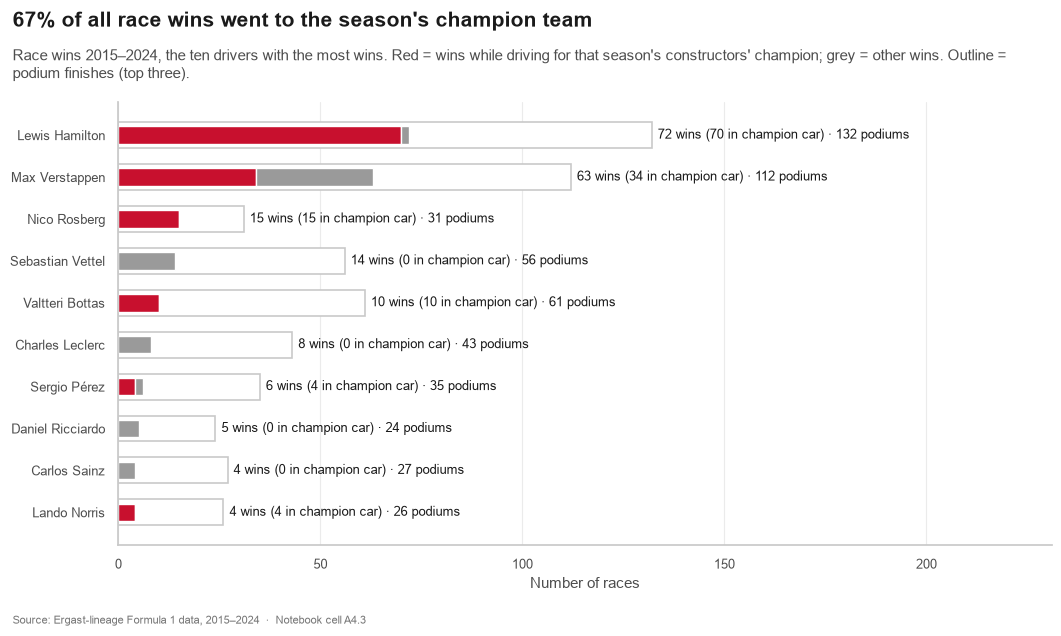

In [28]:
cell("A4.3", "Race wins by driver, and how many came in the champion team's car")
champ_by_year = constructor_final.loc[constructor_final["position"] == 1, ["year", "constructorId"]].rename(
    columns={"constructorId": "champ_id"})
wn = results[results["position"] == 1].merge(champ_by_year, on="year")
wn["in_champ_car"] = wn["constructorId"] == wn["champ_id"]
fact("A4.wins_champ_car", wn["in_champ_car"].mean() * 100, "{:.0f}%")
pods = results[results["is_podium"]].groupby("driverId").size()
wd = (wn.groupby(["driverId", "driver"]).agg(wins=("raceId", "size"), champ_wins=("in_champ_car", "sum"))
      .reset_index("driver").assign(podiums=lambda d: pods.reindex(d.index))
      .sort_values("wins", ascending=False).head(10).set_index("driver"))
display(wd)
fact("A4.n_winners", wn["driverId"].nunique())
fact("A4.top2_wins", wd["wins"].iloc[:2].sum() / len(wn) * 100, "{:.0f}%")
fact("A4.ham_wins", int(wd.loc["Lewis Hamilton", "wins"])); fact("A4.ham_champ_wins", int(wd.loc["Lewis Hamilton", "champ_wins"]))
fact("A4.ver_wins", int(wd.loc["Max Verstappen", "wins"])); fact("A4.ver_champ_wins", int(wd.loc["Max Verstappen", "champ_wins"]))

fig, ax = story_fig(f"{T('A4.wins_champ_car')} of all race wins went to the season's champion team",
                    "Race wins 2015–2024, the ten drivers with the most wins. Red = wins while driving for that season's "
                    "constructors' champion; grey = other wins. Outline = podium finishes (top three).", width=10.5, body=5.0)
a = ax["main"]
y = np.arange(len(wd))[::-1]
a.barh(y, wd["podiums"], height=0.62, color="white", edgecolor=LIGHT, linewidth=1.2, zorder=1)
a.barh(y, wd["champ_wins"], height=0.42, color=RED, zorder=2)
a.barh(y, wd["wins"] - wd["champ_wins"], left=wd["champ_wins"], height=0.42, color=DOT, zorder=2)
for yi, (name, r) in zip(y, wd.iterrows()):
    a.text(r["podiums"] + 1.5, yi, f"{r['wins']} wins ({r['champ_wins']} in champion car) · {r['podiums']} podiums",
           va="center", fontsize=9.5, color=INK)
a.set_yticks(y); a.set_yticklabels(wd.index)
a.set_xlim(0, wd["podiums"].max() * 1.75); a.set_xlabel("Number of races")
a.grid(axis="y", visible=False)
save(fig, "A4_3_wins_by_driver")

**What this means.** 67% of all wins went to whichever team won the constructors' title that year.
Hamilton won 72 races, 70 of them in the champion car.
Verstappen won 63, 34 in the champion car. His 2021 and 2024 wins came in a Red Bull that did *not* win the
constructors' title, which is what a truly great driver looks like in this chart: wins outside the best car.

In [29]:
cell("A4.4", "Driver championship points by season (Plotly)")
top8 = driver_final.groupby("driverId")["points"].sum().nlargest(8).index
dp = driver_final[driver_final["driverId"].isin(top8)]
title_seasons = driver_final[driver_final["position"] == 1]
fact("A4.n_champions", title_seasons["driverId"].nunique())
fact("A4.n_titles", len(title_seasons))
fact("A4.ham_titles", int((title_seasons["driver"] == "Lewis Hamilton").sum()))
fact("A4.ver_titles", int((title_seasons["driver"] == "Max Verstappen").sum()))
fact("A4.ver_2023_pts", driver_final.query("year == 2023 and driver == 'Max Verstappen'")["points"].iloc[0], "{:.0f}")
fig = go.Figure()
for did, g in dp.groupby("driverId"):
    name = g["driver"].iloc[0]
    col, w = (RED, 3) if name == "Max Verstappen" else (INK, 3) if name == "Lewis Hamilton" else (LIGHT, 1.8)
    fig.add_trace(go.Scatter(x=g["year"], y=g["points"], mode="lines+markers", name=name,
                             line=dict(color=col, width=w), marker=dict(size=6, color=col),
                             hovertemplate=f"<b>{name}</b> %{{x}}<br>%{{y:.0f}} points<extra></extra>"))
    t = g[g["position"] == 1]
    if len(t):
        fig.add_trace(go.Scatter(x=t["year"], y=t["points"], mode="markers", hoverinfo="skip", showlegend=False,
                                 marker=dict(symbol="star", size=15, color=col if col != LIGHT else INK2,
                                             line=dict(color="white", width=1.5))))
    last_row = g.sort_values("year").iloc[-1]
    if name in ("Lewis Hamilton", "Max Verstappen"):
        fig.add_annotation(x=last_row["year"], y=last_row["points"], text=f"<b>{name.split()[-1]}</b>", showarrow=False,
                           xanchor="left", xshift=10, font=dict(size=13, color=INK))
fig.update_yaxes(title_text="Championship points", gridcolor=GRID, showgrid=True, rangemode="tozero")
fig.update_xaxes(tickvals=list(range(2015, 2025)), showgrid=False, range=[2014.6, 2025.4])
plotly_story(fig, f"{T('A4.n_titles')} titles, {T('A4.n_champions')} champions: Hamilton's run ended where Verstappen's began",
             "Season points for the eight top scorers of 2015–2024. Stars = world title. Black = Hamilton, red = Verstappen, "
             "grey = others (hover for names).", height=470)
fig.update_layout(showlegend=False)
save_plotly(fig, "A4_4_driver_points")

── Cell A4.4 · Driver championship points by season (Plotly) ──
   [A4.n_champions] 3
   [A4.n_titles] 10
   [A4.ham_titles] 5
   [A4.ver_titles] 4
   [A4.ver_2023_pts] 575
PNG export skipped: RuntimeError 
Image export requires the Kaleido package, v1.0.0 or greater,
which can be installed using pip:

    $ pip install --upgrade "kaleido>=1"



Hamilton won 5 titles and Verstappen 4 (Rosberg took 2016).
The hand-over in 2021 matches the switch between the Mercedes and Red Bull eras in `Cell A4.1`: the driver title follows the car era.

── Cell A4.5 · Driver x circuit heatmap: average finishing position ──
   [A4.hm_n_circuits] 17
   [A4.hm_row_range] 4.6
   [A4.hm_col_range] 1.7
   [A4.hm_best_driver] Lewis Hamilton
   [A4.hm_best_avg] 3.1
   [A4.hm_second_driver] Max Verstappen
   [A4.hm_second_avg] 3.8
   [A4.hm_top2_titles] 9


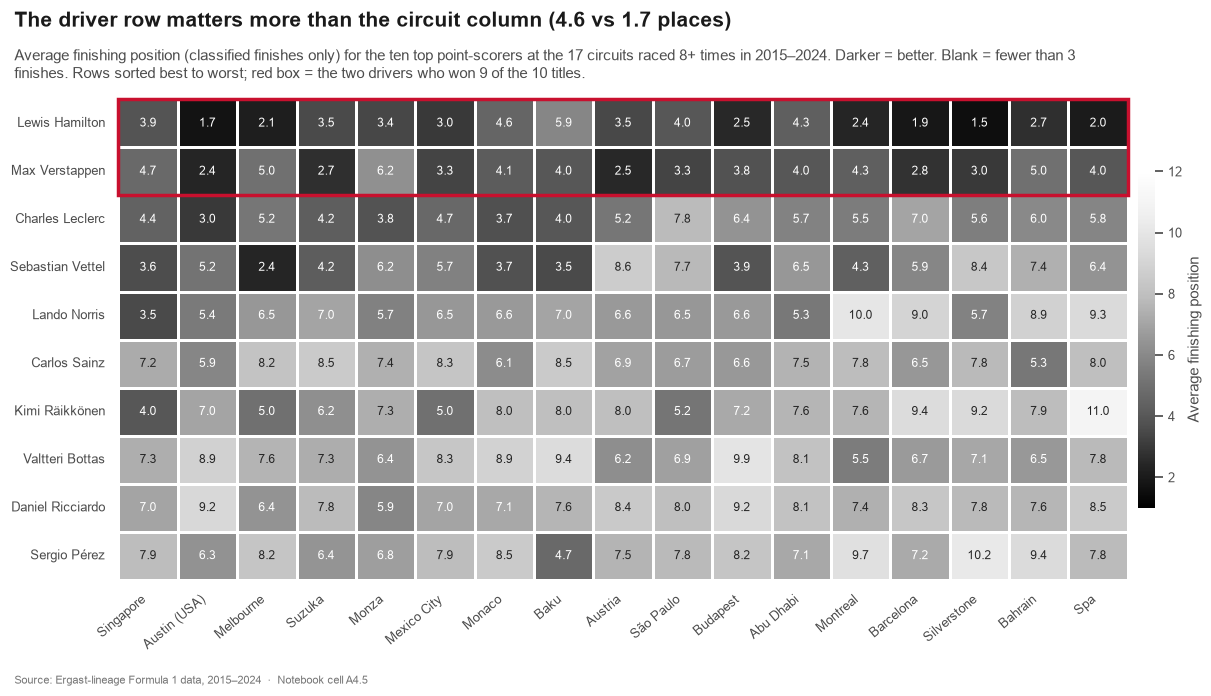

In [30]:
cell("A4.5", "Driver x circuit heatmap: average finishing position")
top10 = results.groupby("driver")["points"].sum().nlargest(10).index
cn = results.groupby("circuit_short")["raceId"].nunique()
regular = cn[cn >= 8].index
hm = (results[results["driver"].isin(top10) & results["circuit_short"].isin(regular) & results["is_classified"]]
      .groupby(["driver", "circuit_short"])["position"].agg(["mean", "size"]))
mean = hm["mean"].unstack().where(hm["size"].unstack() >= 3)
mean = mean.loc[mean.mean(axis=1).sort_values().index, mean.mean(axis=0).sort_values().index]
rows, cols = mean.mean(axis=1), mean.mean(axis=0)
fact("A4.hm_n_circuits", len(regular)); fact("A4.hm_row_range", rows.max() - rows.min(), "{:.1f}")
fact("A4.hm_col_range", cols.max() - cols.min(), "{:.1f}")
fact("A4.hm_best_driver", rows.index[0]); fact("A4.hm_best_avg", rows.iloc[0], "{:.1f}")
fact("A4.hm_second_driver", rows.index[1]); fact("A4.hm_second_avg", rows.iloc[1], "{:.1f}")
fact("A4.hm_top2_titles", int(driver_final[driver_final["position"] == 1]["driver"].isin(rows.index[:2]).sum()))

fig, ax = story_fig(f"The driver row matters more than the circuit column ({T('A4.hm_row_range')} vs {T('A4.hm_col_range')} places)",
                    f"Average finishing position (classified finishes only) for the ten top point-scorers at the "
                    f"{T('A4.hm_n_circuits')} circuits raced 8+ times in 2015–2024. Darker = better. Blank = fewer than 3 finishes. "
                    f"Rows sorted best to worst; red box = the two drivers who won {T('A4.hm_top2_titles')} of the 10 titles.", width=12, body=5.6)
a = ax["main"]
sns.heatmap(mean, annot=True, fmt=".1f", cmap="Greys_r", vmin=1, vmax=12, linewidths=2, linecolor="white",
            annot_kws={"fontsize": 8.5}, cbar_kws={"label": "Average finishing position", "shrink": 0.7, "pad": 0.01}, ax=a)
a.add_patch(mpl.patches.Rectangle((0, 0), mean.shape[1], 2, fill=False, edgecolor=RED, lw=2.5, clip_on=False))
a.set_xlabel(""); a.set_ylabel("")
a.tick_params(axis="x", rotation=40, labelsize=9); a.tick_params(axis="y", labelsize=9.5)
for lab in a.get_xticklabels(): lab.set_ha("right")
save(fig, "A4_5_driver_circuit_heatmap")

**What this means.** Read across a row and the shade barely changes: Lewis Hamilton averages P3.1 and
Max Verstappen P3.8, almost everywhere. Read down a column and it changes a lot.
Row averages span 4.6 places; circuit averages only 1.7.
"Circuit specialists" are mostly a myth at this level: driver *and car* set the level, the circuit nudges it.

**Caveat.** Averages over 3–10 finishes per cell are noisy, and a driver's row mixes several cars over the years.

── Cell A4.6 · Honest anti-climax: lap-time consistency vs season points ──
   [A4.cons_n] 201
   [A4.cons_r] -0.18
   [A4.cons_r2] 3%
   [A4.cons_rho] -0.20
   [A4.cons_r_all] -0.16
   [A4.cons_r_med] -0.40
   [A4.cons_r_race] +0.03
   [A4.cons_r_med_abs] 0.40


,method,r
0,"Main: races with 10+ laps, mean CV",-0.184
1,Keep races with <10 laps,-0.162
2,Median race instead of mean,-0.400
3,Outlier laps filtered per race,0.029


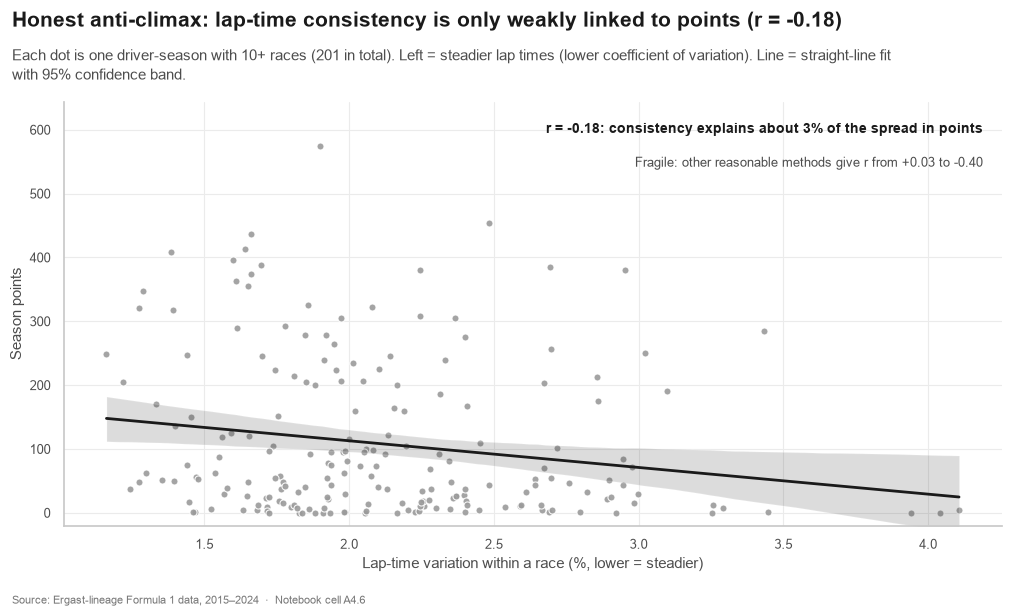

In [31]:
cell("A4.6", "Honest anti-climax: lap-time consistency vs season points")
lt_y = lap_times.merge(races[["raceId", "year"]], on="raceId")

def cv_iqr(x):
    q1, q3 = x.quantile([0.25, 0.75])
    k = x[(x >= q1 - 1.5 * (q3 - q1)) & (x <= q3 + 1.5 * (q3 - q1))]     # drop pit, safety-car, crash laps
    return k.std() / k.mean()                                             # coefficient of variation (CV)

g = lt_y.groupby(["year", "raceId", "driverId"])["lap_ms"]
cv = pd.DataFrame({"cv": g.apply(cv_iqr), "laps": g.size()}).reset_index()

def season_link(c, how="mean"):
    s = (c.groupby(["year", "driverId"]).agg(cv=("cv", how), n=("raceId", "nunique")).reset_index()
         .query("n >= 10").merge(driver_final, on=["year", "driverId"]))
    return s, s["cv"].corr(s["points"])

# Main method: only driver-races with 10+ laps (with 2-3 laps the outlier filter cannot work),
# CV averaged over the season, driver-seasons with 10+ races.
cons, r_c = season_link(cv[cv["laps"] >= 10])
cons["cv_pct"] = cons["cv"] * 100
fact("A4.cons_n", len(cons)); fact("A4.cons_r", r_c, "{:+.2f}"); fact("A4.cons_r2", r_c ** 2 * 100, "{:.0f}%")
fact("A4.cons_rho", stats.spearmanr(cons["cv"], cons["points"])[0], "{:+.2f}")
# Sensitivity: three other reasonable choices
_, r_all = season_link(cv)                                              # keep very short races
_, r_med = season_link(cv[cv["laps"] >= 10], "median")                  # median race, not mean
mask = lt_y.groupby("raceId")["lap_ms"].transform(                      # filter outlier laps per race
    lambda x: x.between(x.quantile(.25) - 1.5 * (x.quantile(.75) - x.quantile(.25)),
                        x.quantile(.75) + 1.5 * (x.quantile(.75) - x.quantile(.25))))
g2 = lt_y[mask].groupby(["year", "raceId", "driverId"])["lap_ms"]
cv2 = pd.DataFrame({"cv": g2.agg(lambda x: x.std() / x.mean()), "laps": g2.size()}).reset_index()
_, r_race = season_link(cv2[cv2["laps"] >= 10])
fact("A4.cons_r_all", r_all, "{:+.2f}"); fact("A4.cons_r_med", r_med, "{:+.2f}"); fact("A4.cons_r_race", r_race, "{:+.2f}")
fact("A4.cons_r_med_abs", abs(r_med), "{:.2f}")
display(pd.DataFrame({"method": ["Main: races with 10+ laps, mean CV", "Keep races with <10 laps",
                                 "Median race instead of mean", "Outlier laps filtered per race"],
                      "r": [r_c, r_all, r_med, r_race]}).round(3))

fig, ax = story_fig(f"Honest anti-climax: lap-time consistency is only weakly linked to points (r = {T('A4.cons_r')})",
                    f"Each dot is one driver-season with 10+ races ({T('A4.cons_n')} in total). Left = steadier lap times "
                    "(lower coefficient of variation). Line = straight-line fit with 95% confidence band.", width=10, body=4.8)
a = ax["main"]
sns.regplot(data=cons, x="cv_pct", y="points", ax=a, ci=95, seed=0,
            scatter_kws=dict(s=26, color=DOT, edgecolor="white", linewidths=0.8, alpha=0.9),
            line_kws=dict(color=INK, lw=2))
a.text(0.98, 0.95, f"r = {T('A4.cons_r')}: consistency explains about {T('A4.cons_r2')} of the spread in points",
       transform=a.transAxes, ha="right", va="top", fontsize=10, color=INK, fontweight="bold")
a.text(0.98, 0.87, f"Fragile: other reasonable methods give r from {T('A4.cons_r_race')} to {T('A4.cons_r_med')}",
       transform=a.transAxes, ha="right", va="top", fontsize=9.5, color=INK2)
a.set_ylim(-20, cons["points"].max() * 1.12)
a.set_xlabel("Lap-time variation within a race (%, lower = steadier)"); a.set_ylabel("Season points")
save(fig, "A4_6_consistency_vs_points")

**An honest anti-climax.** Steadier drivers score slightly more (r = -0.18, 201 driver-seasons), but consistency
explains only about 3% of the spread in points. The result is also **fragile**. Keeping races where a driver did fewer
than 10 laps gives -0.16; using each driver's median race instead of the mean gives -0.40; filtering outlier
laps per race instead of per driver gives +0.03. And even the strongest version is partly a car effect: a fast car
runs in clean air, which steadies its lap times. We report it because a story that only shows its strong results is not honest.
(The earlier analysis reported r ≈ −0.18 without saying how short races were handled; the 10-lap rule reproduces it.
See `verification_log.md`.)

> **The call you would make.** Every edge from Acts 1–3 (a better grid slot, a well-timed stop, reading the alarm) lives
> inside the ceiling the car sets. Fight for every place, but plan the season around the car, not the race.

---
## Act 5 · What the data cannot tell you
### 5a · How a chart can lie: a demonstration
This is the intentionally misleading chart planned for the ethics part of the project:
**constructor championship points with a truncated y-axis**. The data is real and correct. Only the axis is changed.

── Cell A5.1 · MISLEADING chart (for ethics demonstration) ──
   [A5.lead] McLaren
   [A5.second] Ferrari
   [A5.lead_pts] 666
   [A5.second_pts] 652
   [A5.gap] 14
   [A5.gap_pct] 2.1%
   [A5.closest] the closest
   [A5.base] 645
   [A5.visual_ratio] 3.0
   [A5.visual_diff] 200%
   [A5.lie_factor] 93


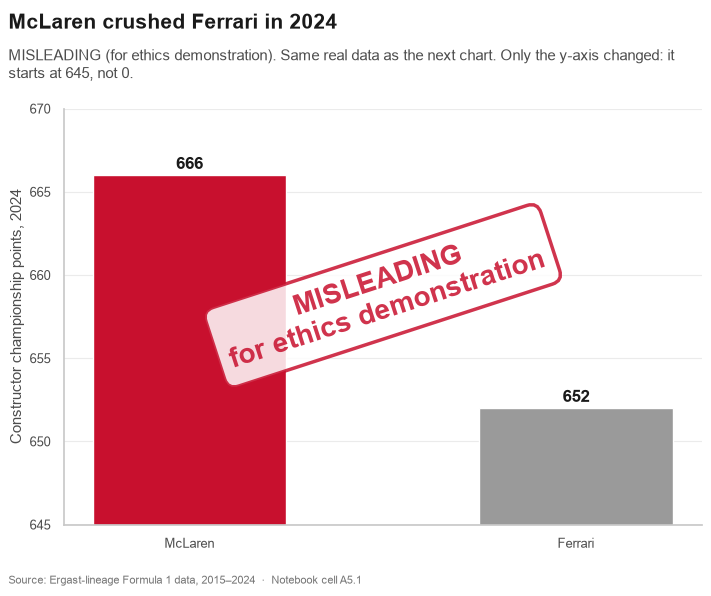

In [32]:
cell("A5.1", "MISLEADING chart (for ethics demonstration)")
c24 = constructor_final[constructor_final["year"] == 2024].sort_values("position").head(2)
(lead, lead_pts), (second, second_pts) = c24[["constructor", "points"]].itertuples(index=False)
gap = lead_pts - second_pts
fact("A5.lead", lead); fact("A5.second", second)
fact("A5.lead_pts", lead_pts, "{:.0f}"); fact("A5.second_pts", second_pts, "{:.0f}")
fact("A5.gap", gap, "{:.0f}"); fact("A5.gap_pct", gap / second_pts * 100, "{:.1f}%")
title_gaps = constructor_final.sort_values("position").groupby("year")["points"].apply(lambda s: s.iloc[0] - s.iloc[1])
rank = int(title_gaps.rank(method="min").loc[2024])
fact("A5.closest", "the closest" if rank == 1 else f"the {rank}th closest")
BASE = 645                                                        # the manipulated axis start
vis_lead, vis_second = lead_pts - BASE, second_pts - BASE
fact("A5.base", BASE); fact("A5.visual_ratio", vis_lead / vis_second, "{:.1f}")
fact("A5.visual_diff", (vis_lead - vis_second) / vis_second * 100, "{:.0f}%")
fact("A5.lie_factor", ((vis_lead - vis_second) / vis_second) / (gap / second_pts), "{:.0f}")

def bars(a, ylim):
    a.bar([lead, second], [lead_pts, second_pts], width=0.5, color=[RED, DOT])
    for i, v in enumerate([lead_pts, second_pts]):
        a.text(i, v + (ylim[1] - ylim[0]) * 0.015, f"{v:.0f}", ha="center", fontsize=12, fontweight="bold", color=INK)
    a.set_ylim(*ylim); a.set_ylabel("Constructor championship points, 2024")
    a.grid(axis="x", visible=False)

fig, ax = story_fig(f"{lead} crushed {second} in 2024",
                    "MISLEADING (for ethics demonstration). Same real data as the next chart. "
                    f"Only the y-axis changed: it starts at {BASE}, not 0.", width=7, body=4.6)
bars(ax["main"], (BASE, 670))
ax["main"].text(0.5, 0.55, "MISLEADING\nfor ethics demonstration", transform=ax["main"].transAxes, ha="center",
                va="center", fontsize=20, fontweight="bold", color=RED, alpha=0.85, rotation=18,
                bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=RED, lw=2.5, alpha=0.85))
save(fig, "A5_1_misleading_truncated_axis")

── Cell A5.2 · HONEST version of the same chart ──


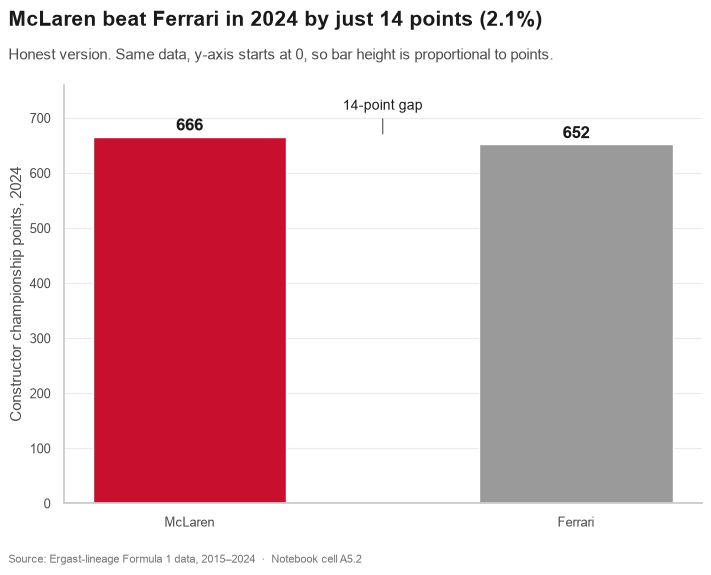

In [33]:
cell("A5.2", "HONEST version of the same chart")
fig, ax = story_fig(f"{lead} beat {second} in 2024 by just {T('A5.gap')} points ({T('A5.gap_pct')})",
                    "Honest version. Same data, y-axis starts at 0, so bar height is proportional to points.",
                    width=7, body=4.6)
bars(ax["main"], (0, 760))
ax["main"].annotate(f"{T('A5.gap')}-point gap", xy=(0.5, lead_pts), xytext=(0.5, 715), ha="center", fontsize=10,
                    color=INK, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
save(fig, "A5_2_honest_full_axis")

── Cell A5.3 · Side by side: misleading vs honest ──


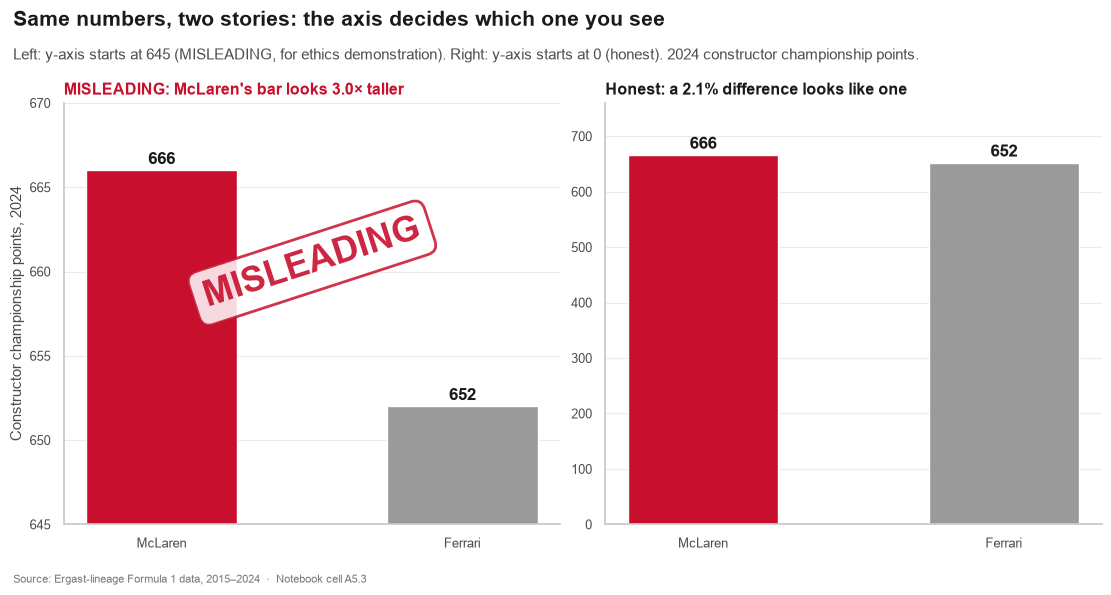

In [34]:
cell("A5.3", "Side by side: misleading vs honest")
fig, ax = story_fig("Same numbers, two stories: the axis decides which one you see",
                    f"Left: y-axis starts at {BASE} (MISLEADING, for ethics demonstration). Right: y-axis starts at 0 (honest). "
                    f"2024 constructor championship points.", width=11, body=4.8, mosaic=[["bad", "good"]])
bars(ax["bad"], (BASE, 670)); bars(ax["good"], (0, 760))
ax["bad"].set_title(f"MISLEADING: {lead}'s bar looks {T('A5.visual_ratio')}× taller", color=RED)
ax["good"].set_title(f"Honest: a {T('A5.gap_pct')} difference looks like one", color=INK)
ax["bad"].text(0.5, 0.62, "MISLEADING", transform=ax["bad"].transAxes, ha="center", va="center", fontsize=26,
               fontweight="bold", color=RED, alpha=0.9, rotation=18, zorder=10,
               bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=RED, lw=2, alpha=0.85))
ax["good"].set_ylabel("")
save(fig, "A5_3_misleading_vs_honest")

**What was manipulated.** Only the y-axis. It starts at 645 points instead of 0. The data is real:
McLaren 666, Ferrari 652.

**Why it misleads.** A bar chart encodes value as *bar length*. When the axis is cut at 645,
we only see the top 666−645 and 652−645 points of each bar. McLaren's bar becomes
3.0 times taller than Ferrari's, while the real difference is 2.1%.

**The false impression.** "McLaren crushed Ferrari." In reality the 2024 constructors' title was the closest of the
ten seasons: 14 points over a 666-point season.

**How it was fixed.** The y-axis starts at zero, the exact values are printed on the bars, and the title states the real size
of the gap (14 points, 2.1%).

**The principle.** *Truthful scaling* and *proportional ink* (Edward Tufte): the size of a mark must be proportional to the
number it shows. Tufte's **lie factor** = (size of the effect in the graphic) ÷ (size of the effect in the data).
An honest chart has a lie factor near 1. Here the bar difference is 200% and the data difference is 2.1%,
a lie factor of about **93**.

**Ethical reflection.** This chart contains no false number, which is what makes it dangerous: it would pass a fact-check of
its labels. Truncated axes are tempting in F1 because so many fights are close, like the 2024 constructors' title.
The same care applies to the rest of this project. Every bar chart here starts at zero. Dot and line charts that do not
start at zero (Acts 1 and 2) encode *position*, not length, and say so. Small samples are flagged (Hockenheim, the large-gap bucket),
and the one weak finding (consistency) is shown, not hidden.

### 5b · The limits of this analysis
| Finding | Type of evidence | What could be behind it | What we can honestly say |
|---|---|---|---|
| Grid predicts finish (Act 1) | Correlation | Fast cars qualify well *and* race well | Starting position and finishing position move together; more at some tracks |
| Undercut pattern (Act 2) | Before/after average | Safety cars, tyre choices, forced stops | Early first stops lose more places at once and recover more |
| Extra stop = alarm (Act 3) | Correlation, strong (z = -7.3) | Damage, punctures, spins, bad timing | An extra stop is a *warning sign*, not a cause and not a tactic |
| Car sets the ceiling (Act 4) | Descriptive | Budget, rules, engine supply | Points share swings by team era far more than by any race decision |
| Consistency (Act 4) | Weak, fragile correlation | Car pace | Little to no link with points |

**Correlation is not causation.** None of these results comes from an experiment. Each one shows that two things move
together in ten seasons of records. The dataset also has no tyre compounds, no weather, no safety-car periods and no team
radio, so the *why* behind an event (like Hamilton's lap-1 stop in the hook race) is always outside the data.

---
## Closing · Back to the hook race

In [35]:
cell("C.1", "The hook race through all four acts")
sh = gf[gf["circuitId"] == races.loc[races["raceId"] == HOOK, "circuitId"].iloc[0]]
fact("C.circuit", sh["circuit_short"].iloc[0])
fact("C.circuit_r", sh["grid"].corr(sh["position"]), "{:.2f}")
fact("C.circuit_races", sh["raceId"].nunique())
fact("C.extra_stops", FACTS["H.ham_stops"]["value"] - FACTS["H.ros_stops"]["value"])

── Cell C.1 · The hook race through all four acts ──
   [C.circuit] Shanghai
   [C.circuit_r] 0.80
   [C.circuit_races] 6
   [C.extra_stops] 3


3

Go back to the 2016 Chinese GP and read it again, this time as a strategist.

- **Act 1.** Rosberg started on pole and won. At Shanghai the grid-finish correlation is 0.80 over 6 races:
  Saturday mattered.
- **Act 2.** On lap 4, 10 cars pitted at once as the race slowed. Those lines crossing in the grey band
  are pit stops trading places now for places later.
- **Act 3.** Hamilton, the slower qualifier in the same car, made 3 more stops than his teammate and finished
  7th. The extra stops were the alarm, not the plan: his first came on lap 1.
- **Act 4.** Both drove the 2016 Mercedes, the car that took 36.1% of all points that season.
  That is how a car from 22nd on the grid still reached the points.

**The 844 position changes were never random. They were a chain of cause and effect, and now you can read it.**

---
## Dashboard · The five acts in one interactive page
`Cell D.1` exports the tables the dashboard needs and writes **`F1_Dashboard.html`**: one self-contained file
(Plotly.js is embedded, so it works offline). Filters for season, constructor, driver and circuit sit in one row at the top
and every chart re-draws for the same slice of data. The page is laid out as the five acts.

In [36]:
cell("D.1", "Build F1_Dashboard.html")
import plotly.offline
def cols(df):                                               # compact column-wise JSON
    return {c: [None if (isinstance(v, float) and np.isnan(v)) else v for v in df[c].tolist()] for c in df.columns}

lap_trace = {}                                             # {raceId: {driverId: [pos on lap 1, 2, ...]}}
for (rid, did), g in lap_times.groupby(["raceId", "driverId"]):
    p = g.set_index("lap")["position"].reindex(range(1, int(g["lap"].max()) + 1))
    lap_trace.setdefault(str(rid), {})[str(did)] = [None if pd.isna(v) else int(v) for v in p]
dash = {
    "races": cols(races[["raceId", "year", "round", "race_label", "circuitId", "circuit_short"]]),
    "drivers": cols(results.drop_duplicates("driverId")[["driverId", "code", "driver"]].sort_values("driver")),
    "constructors": cols(results.drop_duplicates("constructorId")[["constructorId", "constructor"]].sort_values("constructor")),
    "results": cols(race_level[["raceId", "year", "circuitId", "driverId", "constructorId", "grid", "position",
                                "positionOrder", "points", "is_dnf", "n_stops"]].assign(
                                    is_dnf=lambda d: d["is_dnf"].astype(int))),
    "laps": lap_trace,
    "stops": cols(pit_stops[["raceId", "driverId", "lap"]]),
    "undercut": cols(und[["raceId", "year", "circuitId", "driverId", "constructorId", "timing", "chg2", "chg10"]]
                     .assign(timing=lambda d: d["timing"].astype(str))),
    "pairs": cols(bc[["raceId", "year", "circuitId", "constructorId", "slow_id", "fast_id", "q_gap", "stop_diff", "beat"]]
                  .assign(beat=lambda d: (d["beat"] > 0).astype(int))),
    "cfinal": cols(constructor_final[["year", "constructorId", "constructor", "points", "points_share", "position"]]),
    "dfinal": cols(driver_final[["year", "driverId", "driver", "points", "position"]]),
    "circuit_r": cols(byc[["circuitId", "circuit_short", "r", "n", "races", "lo", "hi"]]),
    "facts": {k: v["text"] for k, v in FACTS.items()},
    "hook_race": int(HOOK),
}
template = Path("assets/dashboard_template.html").read_text()
html = (template.replace("/*__PLOTLYJS__*/", plotly.offline.get_plotlyjs())
                .replace("/*__DATA__*/null", json.dumps(dash, separators=(",", ":"), default=float).replace("</", "<\\/")))
Path("F1_Dashboard.html").write_text(html, encoding="utf-8")
fact("D.size_mb", Path("F1_Dashboard.html").stat().st_size / 1e6, "{:.1f}")

── Cell D.1 · Build F1_Dashboard.html ──
   [D.size_mb] 5.9


5.918504

`Cell D.2` repeats one dashboard filter in Python, so the numbers quoted from the dashboard are also produced by the notebook.

In [37]:
cell("D.2", "Dashboard filter example: all races vs Circuit = Monaco")
MON = races.loc[races["circuitRef"] == "monaco", "circuitId"].iloc[0]

def dash_kpis(cid=None):
    r = results if cid is None else results[results["circuitId"] == cid]
    g = r.dropna(subset=["grid", "position"])
    e = und[und["timing"] == "Early"] if cid is None else und[(und["timing"] == "Early") & (und["circuitId"] == cid)]
    b = bc if cid is None else bc[bc["circuitId"] == cid]
    return {"races": r["raceId"].nunique(), "r": g["grid"].corr(g["position"]), "und10": e["chg10"].mean(),
            "und_n": len(e), "extra": b.loc[b["extra"], "beat"].mean(), "no": b.loc[~b["extra"], "beat"].mean(),
            "pairs": len(b), "dnf": r["is_dnf"].mean() * 100}

allk, monk = dash_kpis(), dash_kpis(MON)
display(pd.DataFrame({"All races": allk, "Circuit = Monaco": monk}).round(2))
fact("D.all_dnf", allk["dnf"], "{:.1f}%"); fact("D.all_pairs", allk["pairs"], "{:,}")
fact("D.mon_races", monk["races"]); fact("D.mon_r", monk["r"], "{:.2f}")
fact("D.mon_und10", monk["und10"], "{:+.1f}"); fact("D.mon_und_n", monk["und_n"])
fact("D.mon_extra", monk["extra"], "{:.0f}%"); fact("D.mon_no", monk["no"], "{:.0f}%")
fact("D.mon_pairs", monk["pairs"]); fact("D.mon_dnf", monk["dnf"], "{:.1f}%")
fact("D.mon_n_extra", int(bc.loc[(bc["circuitId"] == MON) & bc["extra"]].shape[0]))
mon_last = races[races["circuitId"] == MON].sort_values("date").iloc[-1]
fact("D.mon_last_race", mon_last["race_label"])
fact("D.mon_last_changes", int(churn.loc[mon_last["raceId"], "position_changes"]), "{:,}")

── Cell D.2 · Dashboard filter example: all races vs Circuit = Monaco ──


,All races,Circuit = Monaco
races,209.00,9.00
r,0.75,0.88
und10,-1.67,-1.49
und_n,1032.00,47.00
extra,12.24,0.00
no,34.22,32.73
pairs,1522.00,66.00
dnf,16.95,17.58


   [D.all_dnf] 16.9%
   [D.all_pairs] 1,522
   [D.mon_races] 9
   [D.mon_r] 0.88
   [D.mon_und10] -1.5
   [D.mon_und_n] 47
   [D.mon_extra] 0%
   [D.mon_no] 33%
   [D.mon_pairs] 66
   [D.mon_dnf] 17.6%
   [D.mon_n_extra] 11
   [D.mon_last_race] 2024 Monaco GP
   [D.mon_last_changes] 30


30

## Facts register
`Cell F.1` saves every number used in the text to `facts.json`, with the cell that produced it.
The report, the slides and the viva sheet read their numbers from this file, so they always match this notebook.

In [38]:
cell("F.1", "Save facts.json and list the charts")
fact("F.n_charts", len(CHART_FILES))
fact("F.n_plotly", sum(Path(v).with_suffix(".html").exists() for v in CHART_FILES.values()))
fact("F.n_static", FACTS["F.n_charts"]["value"] - FACTS["F.n_plotly"]["value"])
Path("facts.json").write_text(json.dumps(FACTS, indent=1, ensure_ascii=False, default=float), encoding="utf-8")
Path("charts/index.json").write_text(json.dumps(CHART_FILES, indent=1))
print(len(FACTS), "facts saved;", len(CHART_FILES), "charts:")
for k, v in CHART_FILES.items():
    print(f"  Cell {k:5s} -> {v}")

── Cell F.1 · Save facts.json and list the charts ──
   [F.n_charts] 15
   [F.n_plotly] 0
   [F.n_static] 15
226 facts saved; 15 charts:
  Cell H.2   -> charts/H2_bump_chart_hook_race.png
  Cell A1.1  -> charts/A1_1_grid_vs_finish_pooled.png
  Cell A1.2  -> charts/A1_2_circuit_lollipop.png
  Cell A2.2  -> charts/A2_2_undercut_slope.png
  Cell A3.2  -> charts/A3_2_stops_vs_finish.png
  Cell A3.3  -> charts/A3_3_gap_vs_stopdiff.png
  Cell A3.4  -> charts/A3_4_teammate_duel.png
  Cell A3.5  -> charts/A3_5_distress_signal.png
  Cell A4.2  -> charts/A4_2_dnf_rate.png
  Cell A4.3  -> charts/A4_3_wins_by_driver.png
  Cell A4.5  -> charts/A4_5_driver_circuit_heatmap.png
  Cell A4.6  -> charts/A4_6_consistency_vs_points.png
  Cell A5.1  -> charts/A5_1_misleading_truncated_axis.png
  Cell A5.2  -> charts/A5_2_honest_full_axis.png
  Cell A5.3  -> charts/A5_3_misleading_vs_honest.png
